## Conformal Risk Control for Startup Success Prediction through Machine Learning

In [1]:
%load_ext autoreload
%autoreload 2

import os
from dotenv import load_dotenv 
import yaml

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.impute import KNNImputer

from src.utils import (to_tensors, get_probs, set_seed,
                       run_conformal_fnr_experiment,
                       run_conformal_fnr_group_calibrated, plot_conformal_fnr,
                       assign_model_colors, fnr_by_group_table,
                       crc_summary_tables, plot_crc_metric_boxplots,
                       plot_fnr_by_group_boxplots, plot_fnr_by_group_lines)


from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from src.models.MLP import MLP


from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score)
import wandb
import matplotlib.pyplot as plt 


import scipy.integrate
if not hasattr(np, 'trapz'):
    np.trapz = scipy.integrate.trapezoid

load_dotenv()

with open('config/config.yaml', 'r') as f:
    config = yaml.safe_load(f)


timeWindow=int(config['time_window'])

lastYear=int(config['last_year'])

conformal_store = {}
conformal_pool_store = {}

## Split, Imputation and Scaling

In [2]:
dataset = pd.read_csv(config["paths"]["dataset_window"])

ids = dataset['CompanyID']
X = dataset.drop(['CompanyID', 'Target'], axis=1)
y = dataset['Target']

train_frac = config['train_frac']
cal_frac   = config['calibration_frac']
val_frac   = config['validation_frac']
test_frac  = config['test_frac']
seed       = config['random_seed']

# Partial split (stratified): train / validation /  calibration & test = 50% / 10% / 20% + 20%.
# Final calibration-test split is done later in the multi-seed robustness check, which re-splits the calibration-test pool 50/50.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, train_size=train_frac, stratify=y, random_state=seed)

X_val, X_cal_test, y_val, y_cal_test = train_test_split( X_tmp, y_tmp, train_size=val_frac, stratify=y_tmp, random_state=seed)


# Imputation (fit on train, apply to all splits)
imputer = KNNImputer(n_neighbors=5)
X_train_imp = imputer.fit_transform(X_train)
X_val_imp   = imputer.transform(X_val)
X_cal_test_imp   = imputer.transform(X_cal_test)
    
# Scaling (fit on imputed train, apply to all splits)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled   = scaler.transform(X_val_imp)
X_cal_test_scaled   = scaler.transform(X_cal_test_imp)



print(f"Total: {len(y)} | Train: {len(y_train)}| Val: {len(y_val)} | Cal+Test: {len(y_cal_test)}")

Total: 30297 | Train: 15148| Val: 1514 | Cal+Test: 13635


## Sweep creation

In [3]:

entity=os.getenv("entity")
project=os.getenv("project")

# Initialize a new sweep
sweep_id = wandb.sweep(config["sweep_settings"],entity=entity, project=project)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/giulio-casti/.netrc.


Create sweep with ID: zq5b9pg7
Sweep URL: https://wandb.ai/giuliocasti-universit-degli-studi-di-cagliari/conformal/sweeps/zq5b9pg7



Definition of the training function to be called by wandb agent.

It will be called multiple times by the wandb agent, each time with a different set of hyperparameters defined in the sweep configuration.

The function trains the specified model, evaluates it on the validation and test sets, logs metrics and plots to Weights & Biases, and computes SHAP values for interpretability.

In [4]:

def train():
    with wandb.init():
        wandb_config = wandb.config

        # Reproducibility: seed Python, NumPy, PyTorch (CPU+CUDA), cuDNN.
        # Sklearn / LightGBM models also get a random_state explicitly below.
        set_seed(config['random_seed'])
        
        # --- RANDOM FOREST ---
        if wandb_config.model_type == "rf":
            model = RandomForestClassifier(
                n_estimators= wandb_config.rf_n_estimators, 
                max_depth= wandb_config.rf_max_depth,  
                min_samples_leaf= wandb_config.rf_min_samples_leaf,
                max_features='log2',
                class_weight='balanced',  
                random_state=config['random_seed']
            )

            model.fit(X_train_imp, y_train)

            preds_train = model.predict(X_train_imp)
            probs_train = model.predict_proba(X_train_imp)[:, 1]
            labels_train = y_train

            probs_cal_test = model.predict_proba(X_cal_test_imp)[:, 1]
            labels_cal_test = y_cal_test

        # --- LGBM ---
        elif wandb_config.model_type == "lgb":
            # Ratio for scale_pos_weight (80/20 -> 4) 
            ratio = float(y_train.value_counts()[0] / y_train.value_counts()[1]) 
            
            model = lgb.LGBMClassifier(
                n_estimators= wandb_config.lgb_n_estimators, 
                learning_rate= wandb_config.learning_rate, 
                max_depth= wandb_config.lgb_max_depth, 
                scale_pos_weight=ratio,  
                min_child_weight= wandb_config.min_child_weight, 
                subsample= wandb_config.subsample,                
                colsample_bytree= wandb_config.colsample_bytree, 
                reg_alpha= wandb_config.reg_alpha, 
                reg_lambda= wandb_config.reg_lambda,
                random_state=config['random_seed'],
            )

            model.fit(X_train_imp, y_train)
            preds_train = model.predict(X_train_imp)
            probs_train = model.predict_proba(X_train_imp)[:, 1]
            labels_train = y_train

            probs_cal_test = model.predict_proba(X_cal_test_imp)[:, 1]
            labels_cal_test = y_cal_test

        # --- DECISION TREE ---
        # elif wandb_config.model_type == "dt":
        #     model = DecisionTreeClassifier(
        #         max_depth=wandb_config.dt_max_depth,
        #         min_samples_leaf=wandb_config.dt_min_samples_leaf,
        #         min_samples_split=wandb_config.dt_min_samples_split,
        #         criterion=wandb_config.dt_criterion,
        #         class_weight='balanced',
        #         random_state=config['random_seed']
        #     )

        #     model.fit(X_train_imp, y_train)
        #     preds_train = model.predict(X_train_imp)
        #     probs_train = model.predict_proba(X_train_imp)[:, 1]
        #     labels_train = y_train

        #     probs_cal_test = model.predict_proba(X_cal_test_imp)[:, 1]
        #     labels_cal_test = y_cal_test

        # --- LOGISTIC REGRESSION  ---
        # elif wandb_config.model_type == "lr":
        #     model = LogisticRegression(
        #         C=wandb_config.lr_C,  
        #         penalty=wandb_config.lr_penalty,
        #         solver='saga',
        #         class_weight='balanced',
        #         max_iter=1000,
        #         random_state=config['random_seed']
        #     )

        #     model.fit(X_train_scaled, y_train)
        #     preds_train = model.predict(X_train_scaled)
        #     probs_train = model.predict_proba(X_train_scaled)[:, 1]
        #     labels_train = y_train

        #     probs_cal_test = model.predict_proba(X_cal_test_scaled)[:, 1]
        #     labels_cal_test = y_cal_test

        elif wandb_config.model_type == "mlp":
            # ── SWEEP HYPERPARAMETERS ──
            hidden_sizes = [int(x) for x in wandb_config.hidden_sizes.split(",")] 
            mlp_lr = wandb_config.mlp_learning_rate 
            mlp_dropout = wandb_config.dropout_rate 
            mlp_wd = wandb_config.weight_decay
            BATCH_SIZE = wandb_config.batch_size 

            # ── TENSOR CONVERSION ──
            X_train_t, y_train_t = to_tensors(X_train_scaled, y_train)
            X_val_t,   y_val_t   = to_tensors(X_val_scaled,   y_val)
            X_cal_test_t,  y_cal_test_t  = to_tensors(X_cal_test_scaled,  y_cal_test)

            # ── DATALOADER ──
            # Seeded generator so that shuffle order is reproducible across runs.
            train_generator = torch.Generator()
            train_generator.manual_seed(config['random_seed'])
            train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                                    batch_size=BATCH_SIZE, shuffle=True,
                                    generator=train_generator)
            val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t),
                                    batch_size=BATCH_SIZE)
            cal_test_loader  = DataLoader(TensorDataset(X_cal_test_t, y_cal_test_t),
                                    batch_size=BATCH_SIZE)

            # ── MODEL, LOSS, OPTIMIZER ──
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

            model = MLP(
                input_size=X_train_scaled.shape[1],
                hidden_sizes=hidden_sizes,
                dropout_rate=mlp_dropout,
                batch_norm=True
            ).to(device)

            # Class weight: pos_weight = n_neg / n_pos (loss balancing)
            n_pos = y_train.sum()
            n_neg = len(y_train) - n_pos
            pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)
            criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

            optimizer = torch.optim.AdamW(model.parameters(), lr=mlp_lr, weight_decay=mlp_wd)
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='max', factor=0.5, patience=5
            )
            # ── TRAINING LOOP ──
            EPOCHS = 100
            best_auc = 0.0
            patience_counter = 0
            EARLY_STOPPING_PATIENCE = 10

            # Temporary path for best model checkpoint
            _tmp_dir = os.path.join(os.getcwd(), "tmp")
            os.makedirs(_tmp_dir, exist_ok=True)
            best_model_path = os.path.join(_tmp_dir, "best_model.pt")

            for epoch in range(EPOCHS):

                # ── Train ──
                model.train()
                train_loss = 0.0

                for X_batch, y_batch in train_loader:
                    X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                    optimizer.zero_grad()
                    preds = model(X_batch)
                    loss  = criterion(preds, y_batch)
                    loss.backward()
                    optimizer.step()

                    train_loss += loss.item() * len(X_batch)

                train_loss /= len(train_loader.dataset)

                # ── Validation ──
                model.eval()
                val_loss = 0.0
                all_preds, all_labels = [], []

                with torch.no_grad():
                    for X_batch, y_batch in val_loader:
                        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                        logits = model(X_batch)
                        loss   = criterion(logits, y_batch)
                        val_loss += loss.item() * len(X_batch)

                        probs = torch.sigmoid(logits).cpu().numpy()
                        all_preds.extend(probs)
                        all_labels.extend(y_batch.cpu().numpy())

                val_loss /= len(val_loader.dataset)
                val_auc   = roc_auc_score(all_labels, all_preds)
                val_f1    = f1_score(all_labels, (np.array(all_preds) > 0.5).astype(int))

                scheduler.step(val_auc)

                print(f"Epoch {epoch+1:3d} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Val Loss: {val_loss:.4f} | "
                    f"Val AUC: {val_auc:.4f} | "
                    f"Val F1: {val_f1:.4f}")

                # ── Early Stopping + Best Model ──
                if val_auc > best_auc:
                    best_auc = val_auc
                    patience_counter = 0
                    torch.save(model.state_dict(), best_model_path)
                else:
                    patience_counter += 1
                    if patience_counter >= EARLY_STOPPING_PATIENCE:
                        print(f"\nEarly stopping at epoch {epoch+1}. Best AUC: {best_auc:.4f}")
                        break
            # ── EVALUATION ──
            model.load_state_dict(torch.load(best_model_path, weights_only=True))
            if os.path.exists(best_model_path):
                os.remove(best_model_path)
            model.eval()

            probs_train, labels_train = get_probs(train_loader, model, device)
            preds_train = (probs_train >= 0.5).astype(int)

            probs_cal_test,  labels_cal_test  = get_probs(cal_test_loader,  model, device)

        # Training-set fit indicators (constant across seeds): overfitting check.
        acc_train = accuracy_score(labels_train, preds_train)
        try:
            auc_train = roc_auc_score(labels_train, probs_train)
        except ValueError:
            auc_train = float("nan")

        wandb.log({"accuracy_train": acc_train, "AUC_train": auc_train})
        print(f"Train accuracy: {acc_train:.3f} | Train AUC: {auc_train:.3f}")

        # ── CONFORMAL RISK CONTROL ON FNR ──
        # Per-run metrics come from the conformal experiment on the cal+test
        # pool: for every seed a base row (no calibration, 0.5 threshold) and
        # one row per target alpha (conformal threshold t*). Metrics: AUC
        # (base only, threshold-free), accuracy, precision, recall, f1, FNR, FPR.
        conf_cfg = config.get("conformal", {})
        if conf_cfg.get("enabled", False):

            df_conf = run_conformal_fnr_experiment(
                probs_cal_test, labels_cal_test,
                alphas=conf_cfg["alpha"],
                seeds=conf_cfg["seeds"],
            )

            fig_conf = plot_conformal_fnr(df_conf, model_name=wandb_config.model_type)

            # Run-level scalars (mean over seeds): pre- (base, 0.5) and
            # post-calibration (t* per alpha).
            base = df_conf[~df_conf["calibrated"]]
            conf_log = {
                "conformal/AUC":            float(base["AUC"].mean()),
                "conformal/base/accuracy":  float(base["accuracy"].mean()),
                "conformal/base/precision": float(base["precision"].mean()),
                "conformal/base/recall":    float(base["recall"].mean()),
                "conformal/base/f1":        float(base["f1"].mean()),
                "conformal/base/FNR":       float(base["FNR"].mean()),
                "conformal/base/FPR":       float(base["FPR"].mean()),
            }
            for a in conf_cfg["alpha"]:
                sub = df_conf[df_conf["calibrated"] & (df_conf["alpha"] == a)]
                conf_log[f"conformal/conf/a{a}/accuracy"]  = float(sub["accuracy"].mean())
                conf_log[f"conformal/conf/a{a}/precision"] = float(sub["precision"].mean())
                conf_log[f"conformal/conf/a{a}/recall"]    = float(sub["recall"].mean())
                conf_log[f"conformal/conf/a{a}/f1"]        = float(sub["f1"].mean())
                conf_log[f"conformal/conf/a{a}/FNR"]       = float(sub["FNR"].mean())
                conf_log[f"conformal/conf/a{a}/FPR"]       = float(sub["FPR"].mean())
                conf_log[f"conformal/conf/a{a}/threshold"] = float(sub["threshold"].mean())

            wandb.log({
                "conformal_fnr_table": wandb.Table(dataframe=df_conf),
                "conformal_fnr_plot": wandb.Image(fig_conf),
                **conf_log,
            })
            plt.close(fig_conf)

            mean_fnr = df_conf[df_conf["calibrated"]].groupby("alpha")["FNR"].mean()
            print("Conformal FNR control (mean realized FNR per alpha):")
            print(mean_fnr.to_string())

            conformal_store[wandb_config.model_type] = df_conf
            conformal_pool_store[wandb_config.model_type] = probs_cal_test

number_of_runs = 3

wandb.agent(sweep_id, function=train, count=number_of_runs)

## RQ1 — Global-level CRC

For each model: the aggregated (mean over seeds) realized test FNR per target
`alpha` and the corresponding plot. Points on/under the `y = x` diagonal mean the
risk `E[FNR_test] <= alpha` is controlled across calibration/test re-splits.

=== RF ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.795,0.731,0.567,0.688,0.621,0.312,0.248


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.249,0.516,0.395,0.952,0.558,0.048,0.690
0.10,0.313,0.590,0.434,0.903,0.586,0.097,0.557
0.15,0.370,0.647,0.472,0.853,0.608,0.147,0.451
0.20,0.412,0.680,0.501,0.805,0.617,0.195,0.379
0.25,0.452,0.709,0.532,0.755,0.624,0.245,0.313


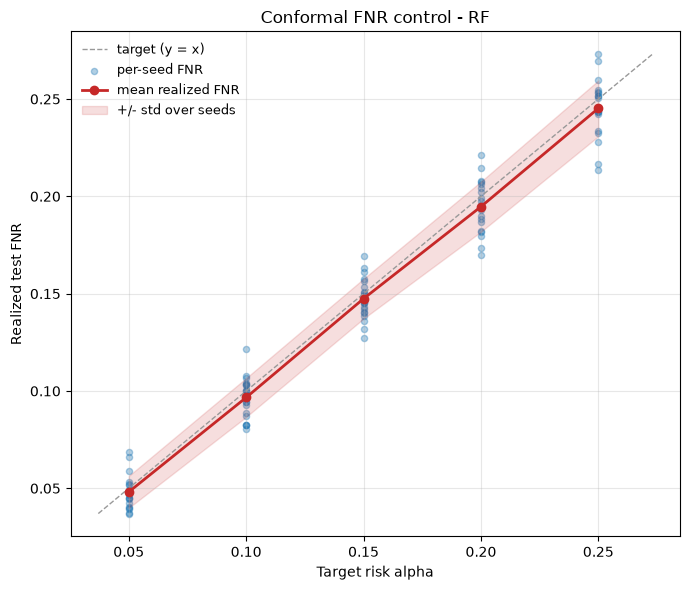

=== LGB ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.798,0.731,0.565,0.7,0.626,0.3,0.254


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.216,0.513,0.393,0.953,0.557,0.047,0.694
0.10,0.288,0.598,0.438,0.905,0.591,0.095,0.547
0.15,0.345,0.649,0.474,0.854,0.610,0.146,0.448
0.20,0.397,0.682,0.503,0.806,0.619,0.194,0.376
0.25,0.447,0.711,0.535,0.756,0.626,0.244,0.310


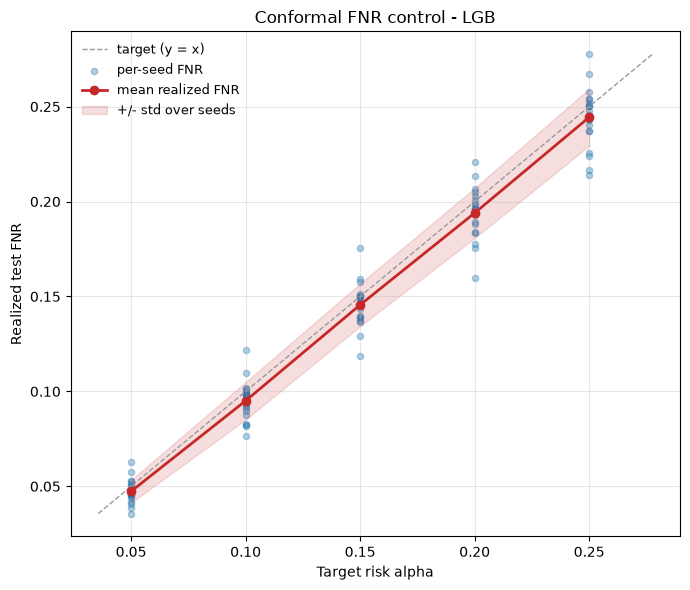

=== MLP ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.789,0.721,0.549,0.717,0.622,0.283,0.278


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,0.214,0.500,0.387,0.952,0.550,0.048,0.713
0.10,0.286,0.581,0.428,0.902,0.580,0.098,0.570
0.15,0.348,0.635,0.463,0.855,0.600,0.145,0.469
0.20,0.407,0.676,0.497,0.806,0.615,0.194,0.385
0.25,0.458,0.704,0.527,0.755,0.621,0.245,0.320


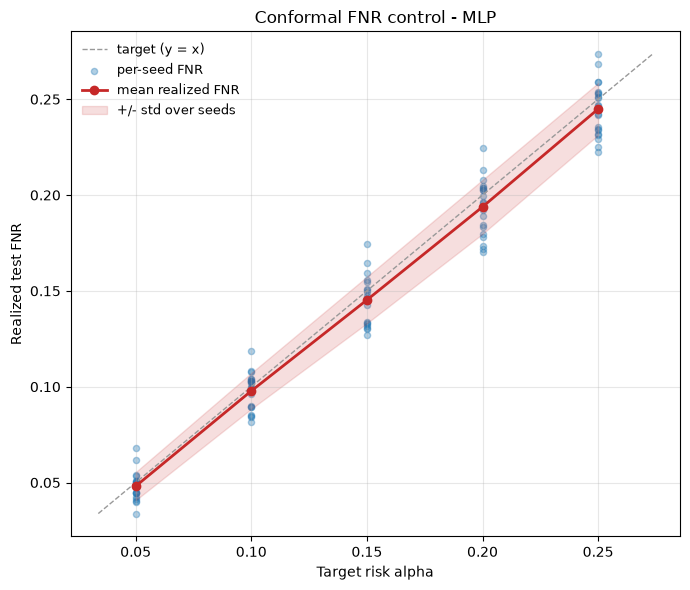

In [5]:
for model_type, df_conf in conformal_store.items():
    print(f"=== {model_type.upper()} ===")
    base, conf = crc_summary_tables(df_conf)
    print("Pre-calibration metrics (mean over seeds):")
    display(base)
    print("Post-calibration metrics per target alpha (mean over seeds):")
    display(conf)
    plot_conformal_fnr(df_conf, model_name=model_type)
    plt.show()

### Global-level CRC boxplots

Per-metric seed-to-seed distribution. One figure per metric; boxes grouped by
model, the first (gray) box the uncalibrated baseline (0.5) then one box per
target `alpha` at the conformal threshold.

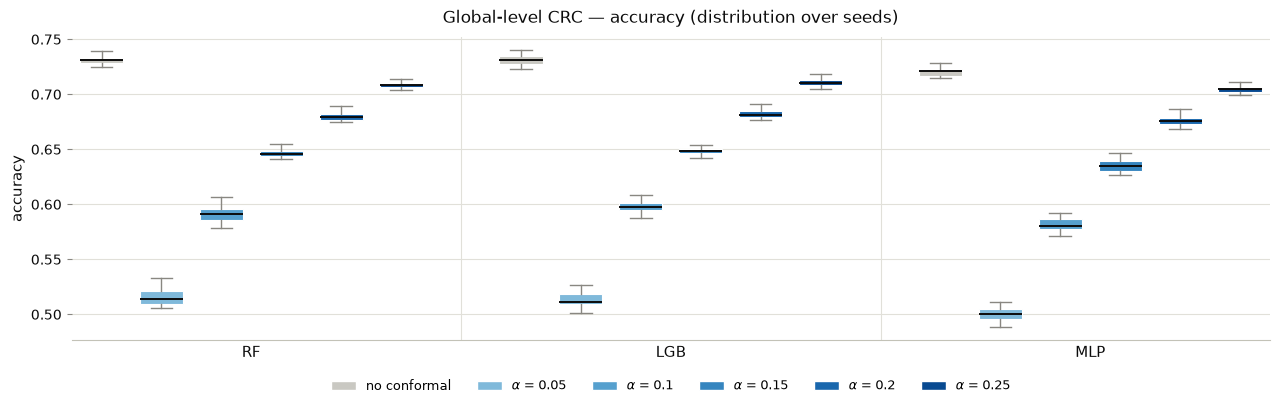

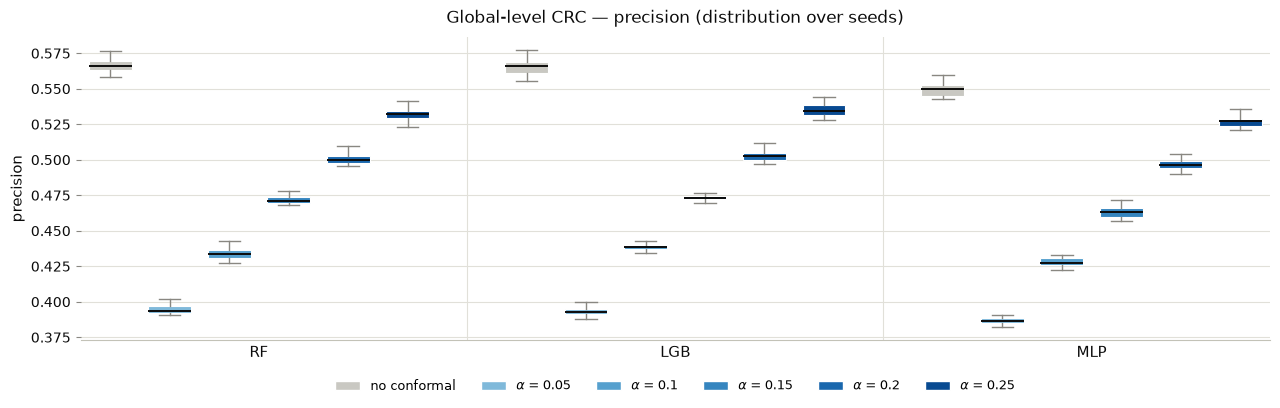

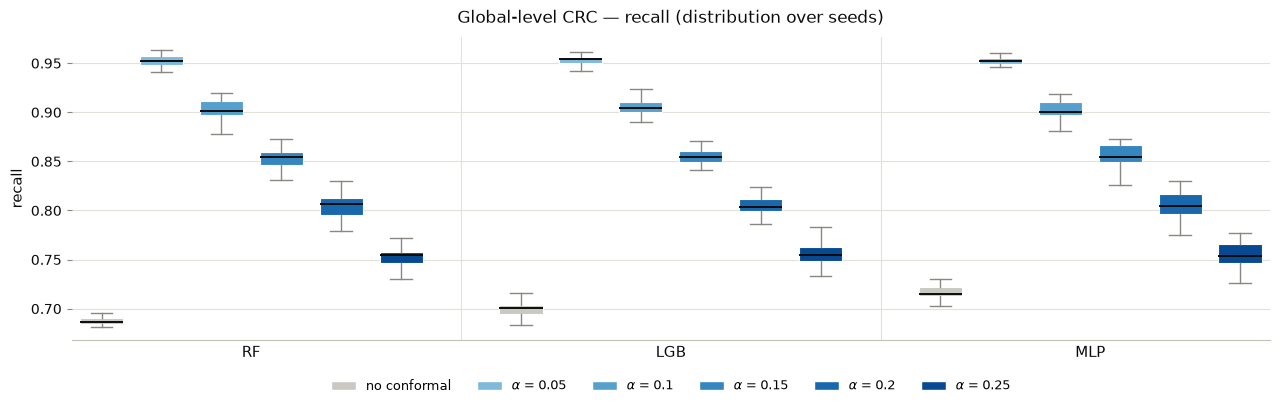

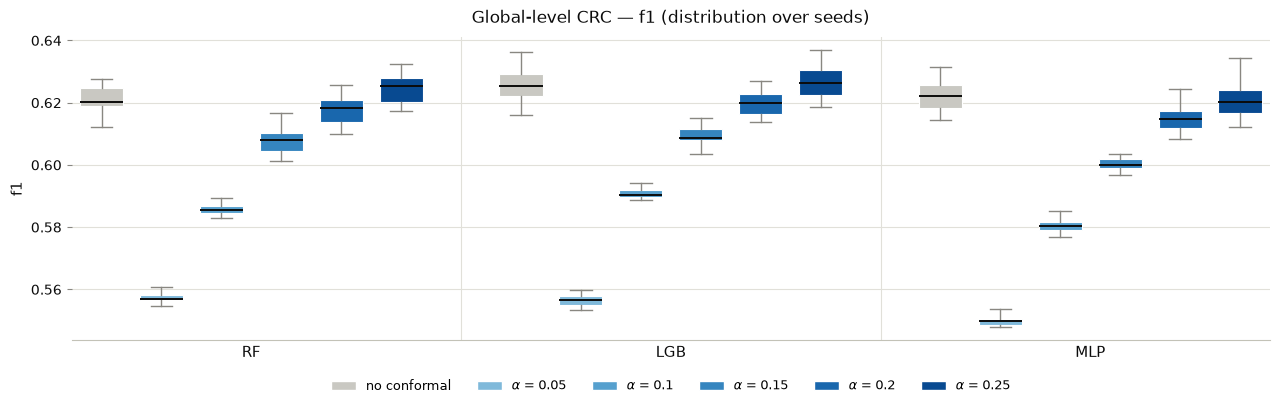

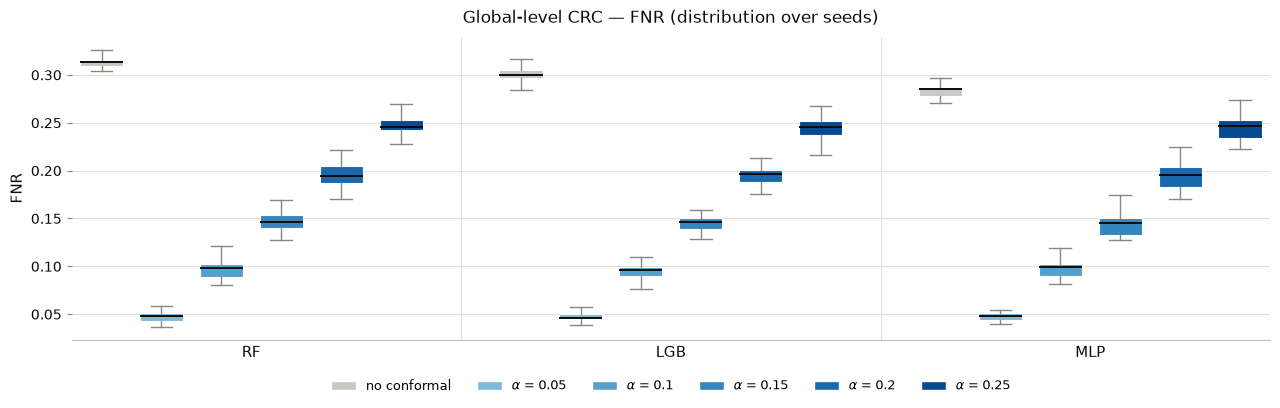

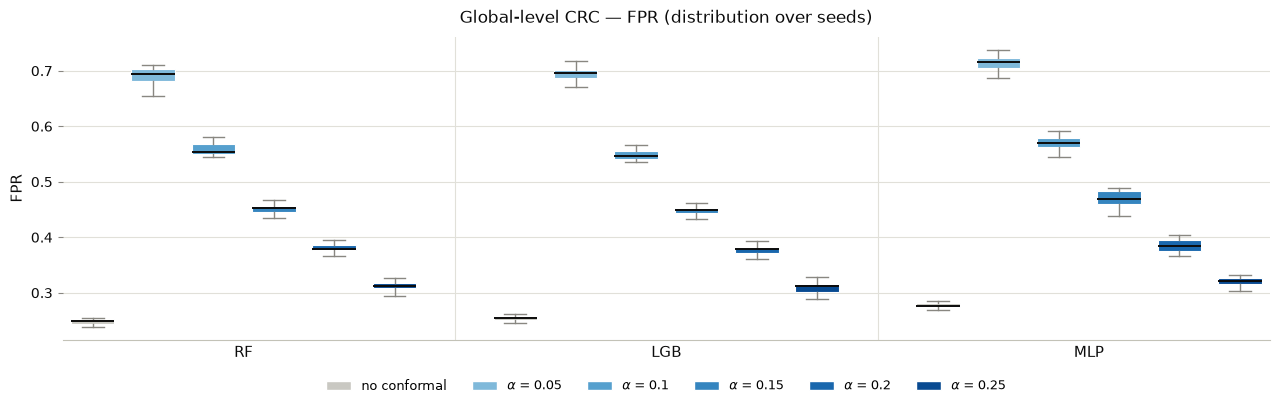

In [6]:
# Global-level CRC: per-metric boxplots over seeds (one representative frame per
# model; the pool is fixed so every model's frame carries the same seeds).
model_df = {}
for model_type, df_conf in conformal_store.items():
    model_df.setdefault(model_type, df_conf)
plot_crc_metric_boxplots(model_df)

## RQ2 — Subgroups under global-level CRC

Characterization of subgroups when the FNR is controlled **marginally** (a single
global threshold). For each model the tables and plots report the realized FNR per
industry sector and per founding-year cohort (`YearFounded`); where `FNR_marg`
sits above the target `alpha`, that subgroup is under-covered by marginal-only
control.

In [7]:
# Group labels on the conformal pool (calibration + test rows, in pool order).
# Reused across models, since the pool is fixed.
pool_index   = X_cal_test.index
cohort_pool  = dataset.loc[pool_index, "YearFounded"].to_numpy()
labels_pool  = y_cal_test.to_numpy()

# Named industry sector recovered from the precomputed frequency->name lookup
# (the frequency uniquely identifies the sector), so we never re-read the raw
# panel (see config["paths"]["sector_freq_map"]).
_freq_to_sector = (pd.read_csv(config["paths"]["sector_freq_map"])
                     .set_index("PrimaryIndustrySectorFreq")["PrimaryIndustrySector"])
sector_freq_pool = dataset.loc[pool_index, "PrimaryIndustrySectorFreq"].to_numpy()
sector_pool = _freq_to_sector.reindex(sector_freq_pool).to_numpy()

alphas = config["conformal"]["alpha"]
seeds  = config["conformal"]["seeds"]

model_color = assign_model_colors(list(conformal_pool_store))

# Compute the per-(model, dimension) tables once; keep the raw per-seed marginal
# AND conditional frames (the latter feeds RQ3). Sector first, then cohort.
subgroup_dims = [("Industry sector", sector_pool),
                 ("YearFounded cohort", cohort_pool)]
subgroup_tables = {}
subgroup_raw_marg = {}
subgroup_raw_cond = {}
for model_type, probs_pool in conformal_pool_store.items():
    for dim_name, groups in subgroup_dims:
        tab, raw_marg, raw_cond = fnr_by_group_table(
            probs_pool, labels_pool, groups, alphas, seeds, min_group=20)
        subgroup_tables[(model_type, dim_name)] = tab
        subgroup_raw_marg[(model_type, dim_name)] = raw_marg
        subgroup_raw_cond[(model_type, dim_name)] = raw_cond

### Marginal coverage per subgroup

A positive `FNR_marg - alpha` is the per-group coverage gap left by the single
marginal threshold (blank when the group is at/under `alpha`).

=== RF — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,B2B,0.05,0.061,0.011,2183,581
1,B2C,0.05,0.085,0.035,3136,823
2,Energy,0.05,0.026,NaN,295,100
3,Financial Services,0.05,0.008,NaN,278,116
4,Healthcare,0.05,0.016,NaN,1618,693
5,Information Technology,0.05,0.045,NaN,5883,1966
6,Materials and Resources,0.05,0.019,NaN,242,95
7,B2B,0.10,0.131,0.031,2183,581
8,B2C,0.10,0.159,0.059,3136,823
9,Energy,0.10,0.054,NaN,295,100


=== LGB — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,B2B,0.05,0.066,0.016,2183,581
1,B2C,0.05,0.072,0.022,3136,823
2,Energy,0.05,0.016,NaN,295,100
3,Financial Services,0.05,0.008,NaN,278,116
4,Healthcare,0.05,0.016,NaN,1618,693
5,Information Technology,0.05,0.047,NaN,5883,1966
6,Materials and Resources,0.05,0.037,NaN,242,95
7,B2B,0.10,0.139,0.039,2183,581
8,B2C,0.10,0.151,0.051,3136,823
9,Energy,0.10,0.027,NaN,295,100


=== MLP — Industry sector ===


,Industry sector,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,B2B,0.05,0.054,0.004,2183,581
1,B2C,0.05,0.075,0.025,3136,823
2,Energy,0.05,0.043,NaN,295,100
3,Financial Services,0.05,0.009,NaN,278,116
4,Healthcare,0.05,0.022,NaN,1618,693
5,Information Technology,0.05,0.047,NaN,5883,1966
6,Materials and Resources,0.05,0.060,0.010,242,95
7,B2B,0.10,0.120,0.020,2183,581
8,B2C,0.10,0.151,0.051,3136,823
9,Energy,0.10,0.084,NaN,295,100


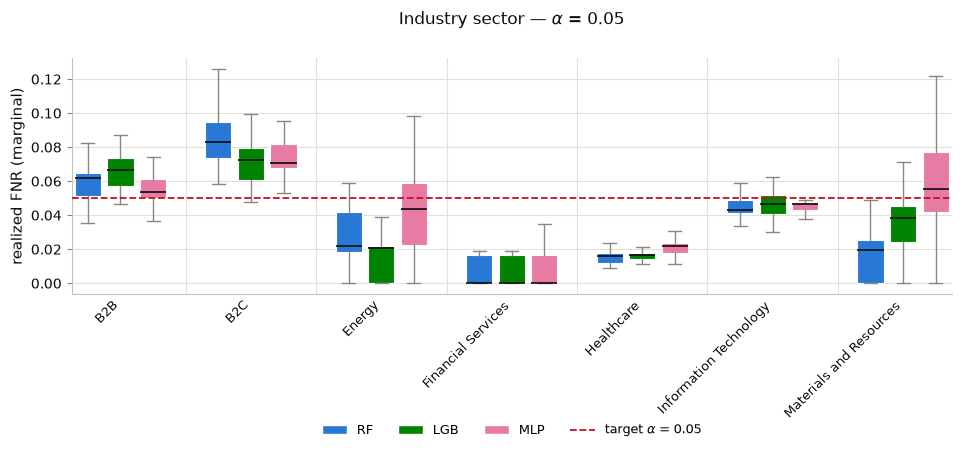

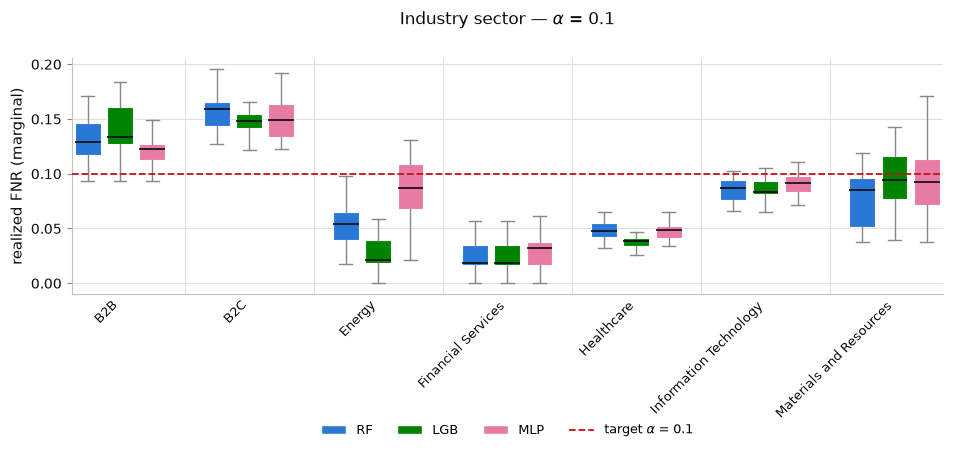

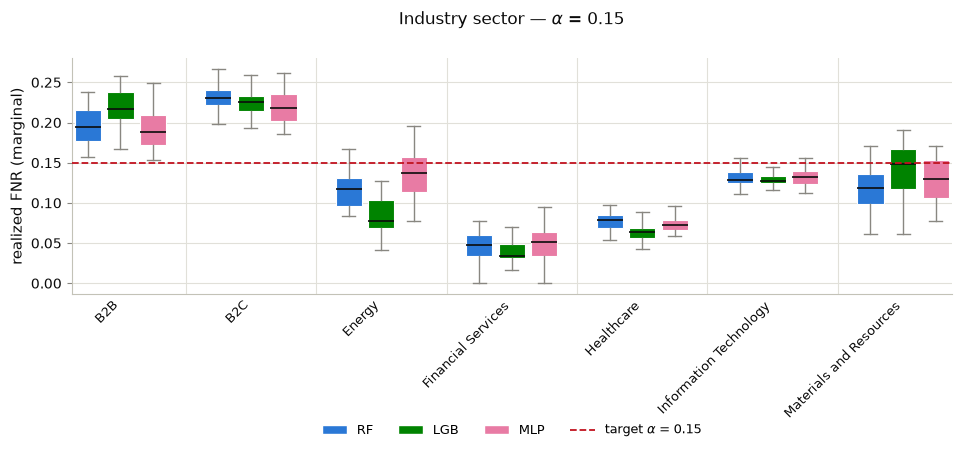

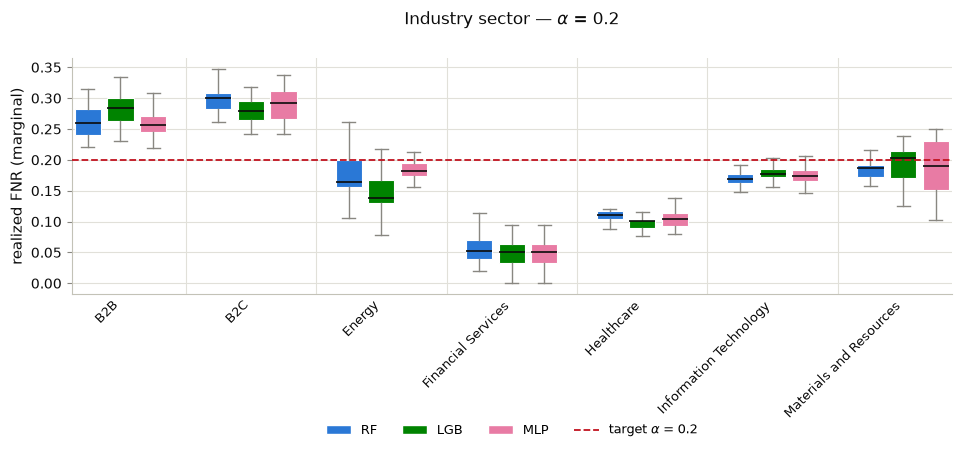

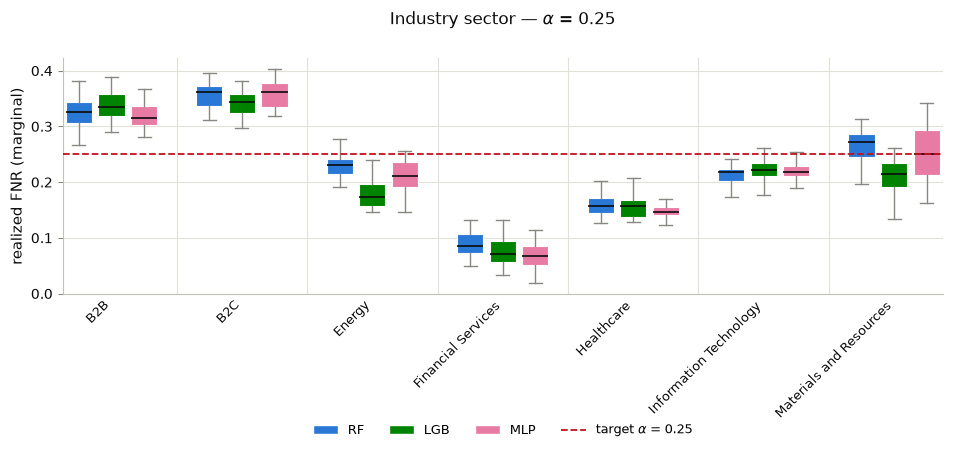

In [8]:
# Industry sector — table then grouped boxplot (models side by side, one figure
# per alpha).
marg_cols = ["group", "alpha", "FNR_marg", "FNR_marg - alpha",
             "n_pool", "n_pos_pool"]
dim_name = "Industry sector"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} ===")
    display(tab[marg_cols].rename(columns={"group": dim_name}))

sector_raw = {m: raw for (m, d), raw in subgroup_raw_marg.items() if d == dim_name}
plot_fnr_by_group_boxplots(sector_raw, dim_name, model_color,
                           ylabel="realized FNR (marginal)")

In [9]:
# (Industry-sector boxplot is produced by the previous cell.)

=== RF — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.000,NaN,55,26
1,2009,0.05,0.007,NaN,240,102
2,2010,0.05,0.024,NaN,871,313
3,2011,0.05,0.047,NaN,1208,363
4,2012,0.05,0.057,0.007,1541,450
5,2013,0.05,0.052,0.002,1828,591
6,2014,0.05,0.056,0.006,2122,721
7,2015,0.05,0.043,NaN,2420,758
8,2016,0.05,0.050,NaN,2032,701
9,2017,0.05,0.060,0.010,1318,349


=== LGB — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.000,NaN,55,26
1,2009,0.05,0.007,NaN,240,102
2,2010,0.05,0.037,NaN,871,313
3,2011,0.05,0.069,0.019,1208,363
4,2012,0.05,0.068,0.018,1541,450
5,2013,0.05,0.049,NaN,1828,591
6,2014,0.05,0.049,NaN,2122,721
7,2015,0.05,0.039,NaN,2420,758
8,2016,0.05,0.040,NaN,2032,701
9,2017,0.05,0.048,NaN,1318,349


=== MLP — YearFounded cohort ===


,YearFounded cohort,alpha,FNR_marg,FNR_marg - alpha,n_pool,n_pos_pool
0,2008,0.05,0.000,NaN,55,26
1,2009,0.05,0.025,NaN,240,102
2,2010,0.05,0.043,NaN,871,313
3,2011,0.05,0.050,NaN,1208,363
4,2012,0.05,0.064,0.014,1541,450
5,2013,0.05,0.054,0.004,1828,591
6,2014,0.05,0.051,0.001,2122,721
7,2015,0.05,0.040,NaN,2420,758
8,2016,0.05,0.042,NaN,2032,701
9,2017,0.05,0.055,0.005,1318,349


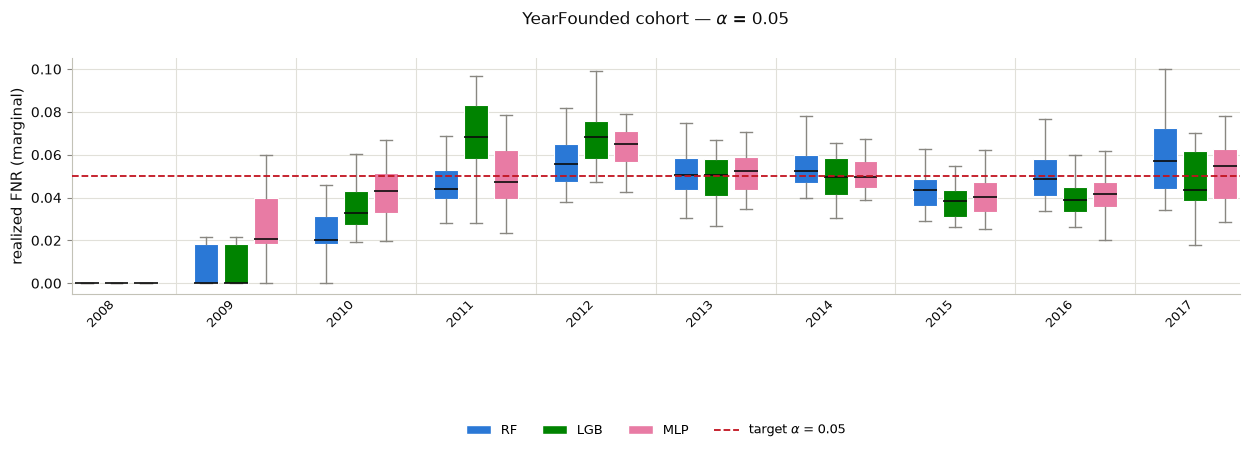

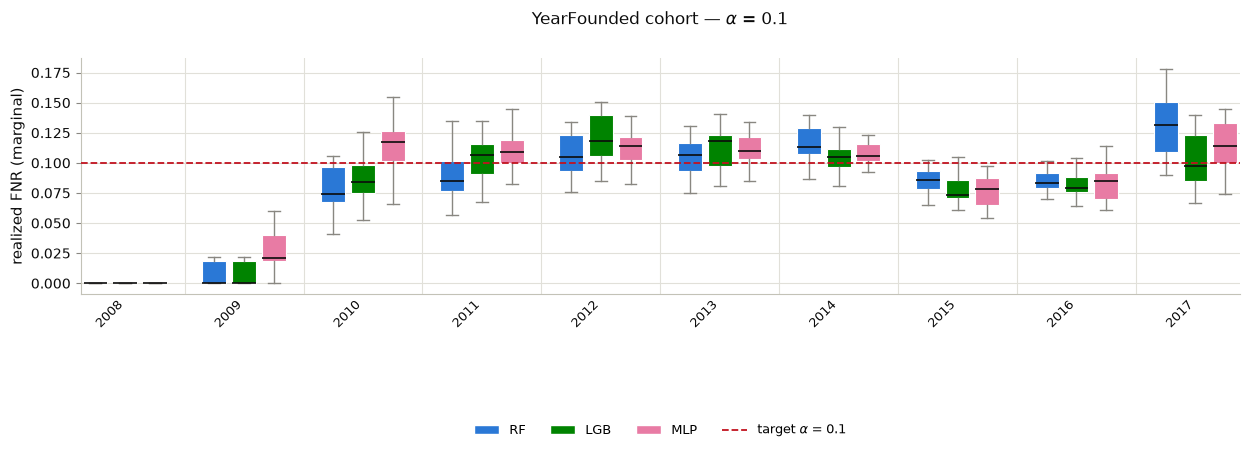

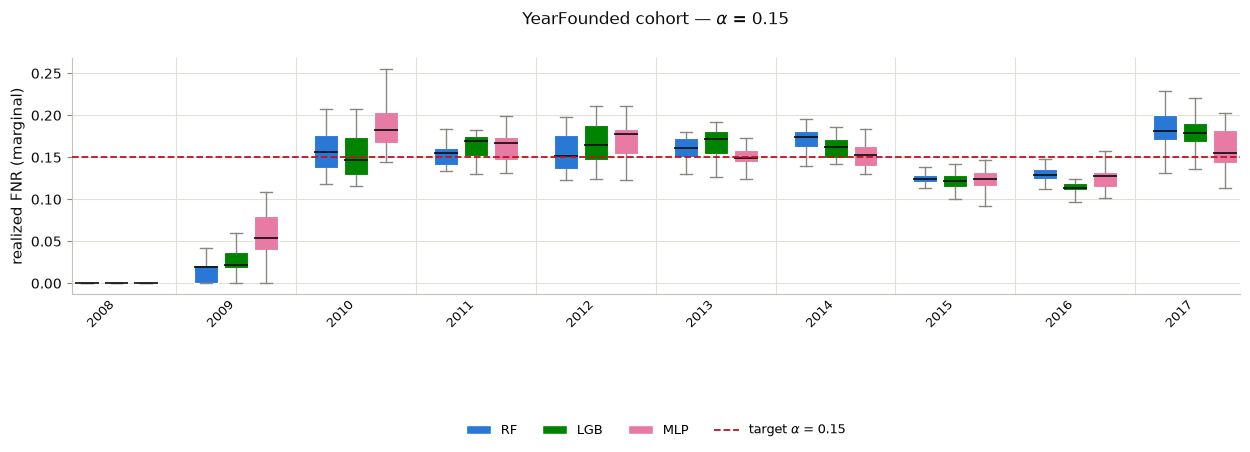

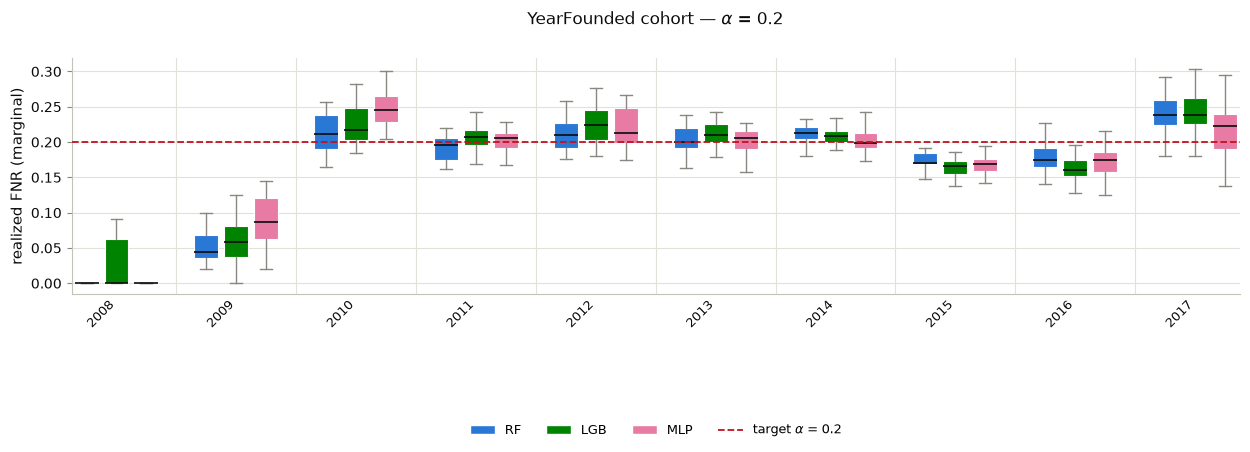

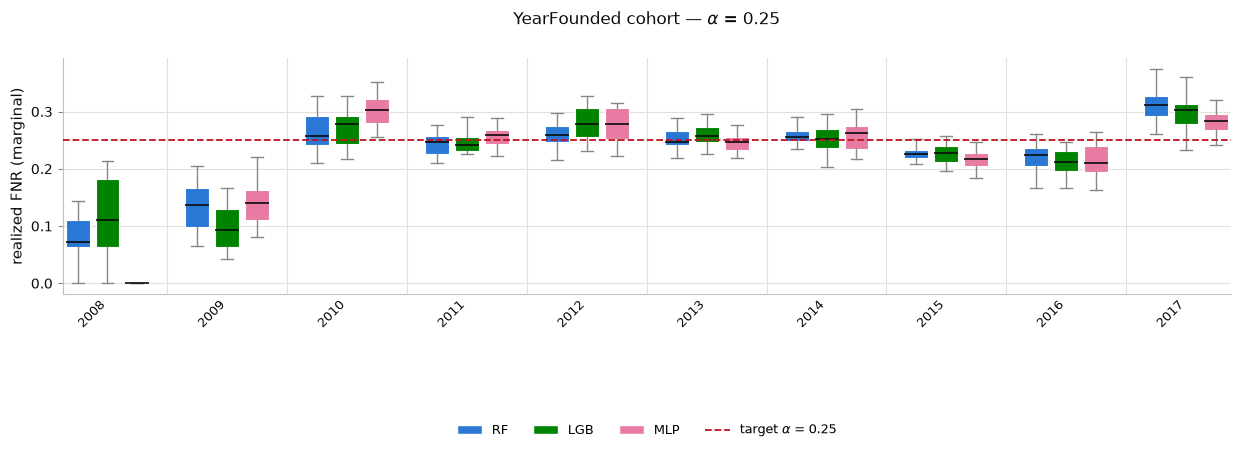

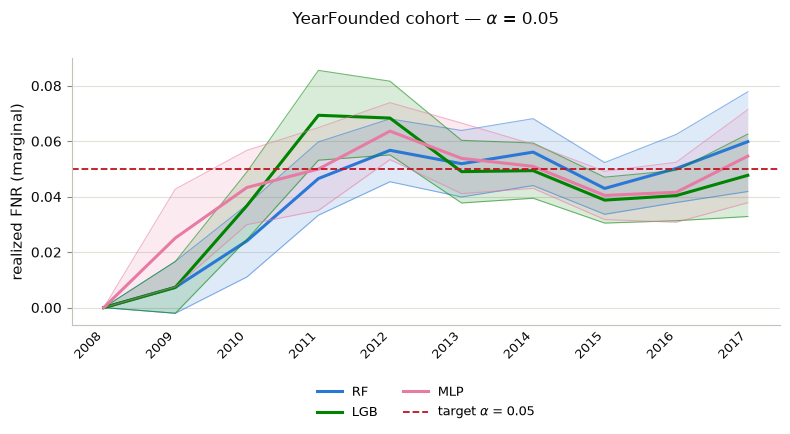

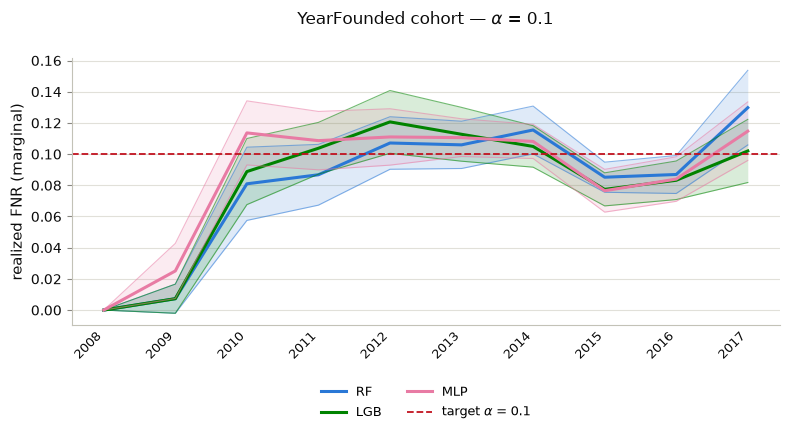

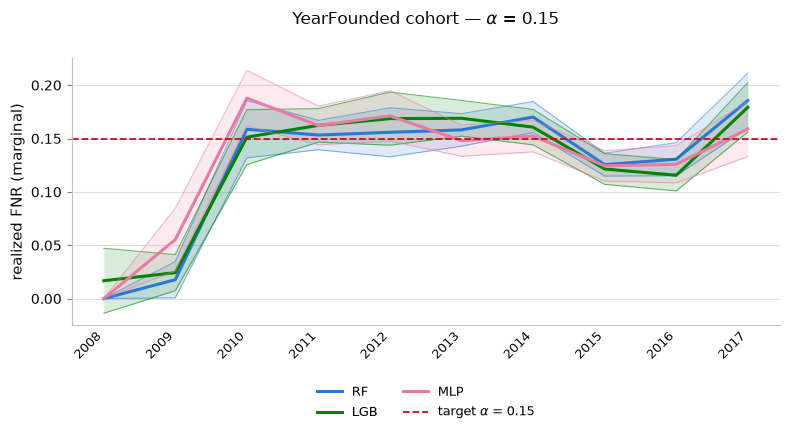

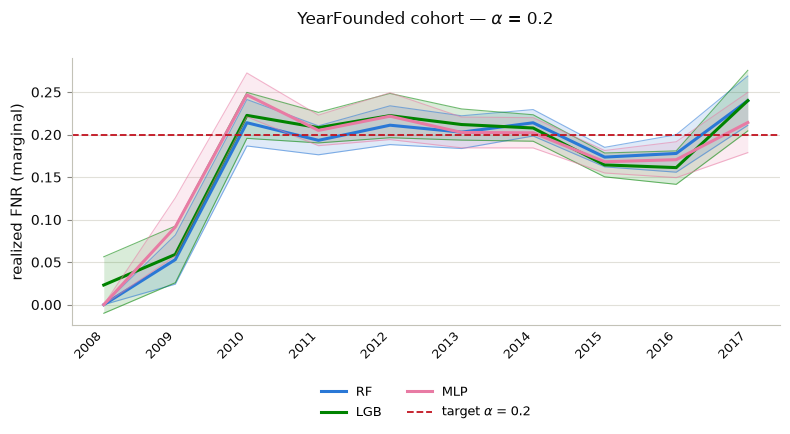

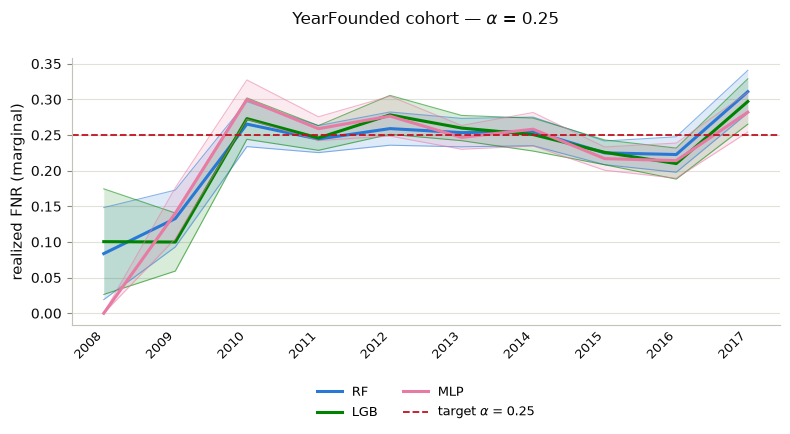

In [10]:
# YearFounded cohort — table, grouped boxplot, then per-model line plot.
marg_cols = ["group", "alpha", "FNR_marg", "FNR_marg - alpha",
             "n_pool", "n_pos_pool"]
dim_name = "YearFounded cohort"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} ===")
    display(tab[marg_cols].rename(columns={"group": dim_name}))

cohort_raw = {m: raw for (m, d), raw in subgroup_raw_marg.items() if d == dim_name}
plot_fnr_by_group_boxplots(cohort_raw, dim_name, model_color,
                           ylabel="realized FNR (marginal)")
plot_fnr_by_group_lines(cohort_raw, dim_name, model_color,
                        ylabel="realized FNR (marginal)")

## RQ3 — Group-level CRC

Same outputs as RQ1 and RQ2 but after **group-level (Mondrian) calibration**: a
separate conformal threshold is calibrated per subgroup. Grouping is applied both
by industry sector and by founding-year cohort.

### As RQ1 — global metrics under group-level calibration

For each grouping, per-group thresholds are applied and the six metrics are
measured on the whole (pooled) test half, so the tables/boxplots are directly
comparable to RQ1.

In [11]:
# Group-calibrated global CRC per (model, grouping). Reuses the same pool.
group_cal_store = {}
for model_type, probs_pool in conformal_pool_store.items():
    for dim_name, groups in subgroup_dims:
        group_cal_store[(model_type, dim_name)] = run_conformal_fnr_group_calibrated(
            probs_pool, labels_pool, groups, alphas, seeds, min_group=20)

In [12]:
# Summary tables (pre/post) per model, one block per grouping.
for dim_name, _ in subgroup_dims:
    print(f"################  Group-level CRC calibrated by {dim_name}  ################")
    for (model_type, d), df_gc in group_cal_store.items():
        if d != dim_name:
            continue
        print(f"=== {model_type.upper()} — calibrated by {dim_name} ===")
        base, conf = crc_summary_tables(df_gc)
        print("Pre-calibration metrics (mean over seeds):")
        display(base)
        print("Post-calibration metrics per target alpha (mean over seeds):")
        display(conf)

################  Group-level CRC calibrated by Industry sector  ################
=== RF — calibrated by Industry sector ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.795,0.731,0.567,0.688,0.621,0.312,0.248


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.506,0.390,0.953,0.553,0.047,0.705
0.10,NaN,0.586,0.431,0.904,0.584,0.096,0.563
0.15,NaN,0.632,0.460,0.853,0.598,0.147,0.472
0.20,NaN,0.667,0.489,0.805,0.608,0.195,0.398
0.25,NaN,0.694,0.516,0.756,0.613,0.244,0.336


=== LGB — calibrated by Industry sector ===
Pre-calibration metrics (mean over seeds):


...

,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.511,0.392,0.953,0.556,0.047,0.698
0.10,NaN,0.594,0.436,0.907,0.589,0.093,0.554
0.15,NaN,0.642,0.469,0.857,0.606,0.143,0.459
0.20,NaN,0.678,0.499,0.807,0.617,0.193,0.383
0.25,NaN,0.706,0.529,0.755,0.622,0.245,0.317


=== MLP — calibrated by YearFounded cohort ===
Pre-calibration metrics (mean over seeds):


,AUC,accuracy,precision,recall,f1,FNR,FPR
threshold 0.5 (pre),0.789,0.721,0.549,0.717,0.622,0.283,0.278


Post-calibration metrics per target alpha (mean over seeds):


,threshold,accuracy,precision,recall,f1,FNR,FPR
alpha,,,,,,,
0.05,NaN,0.493,0.384,0.955,0.547,0.045,0.725
0.10,NaN,0.573,0.422,0.903,0.576,0.097,0.583
0.15,NaN,0.631,0.460,0.856,0.598,0.144,0.475
0.20,NaN,0.672,0.493,0.807,0.612,0.193,0.392
0.25,NaN,0.700,0.523,0.755,0.618,0.245,0.326


################  Group-level CRC calibrated by Industry sector  ################


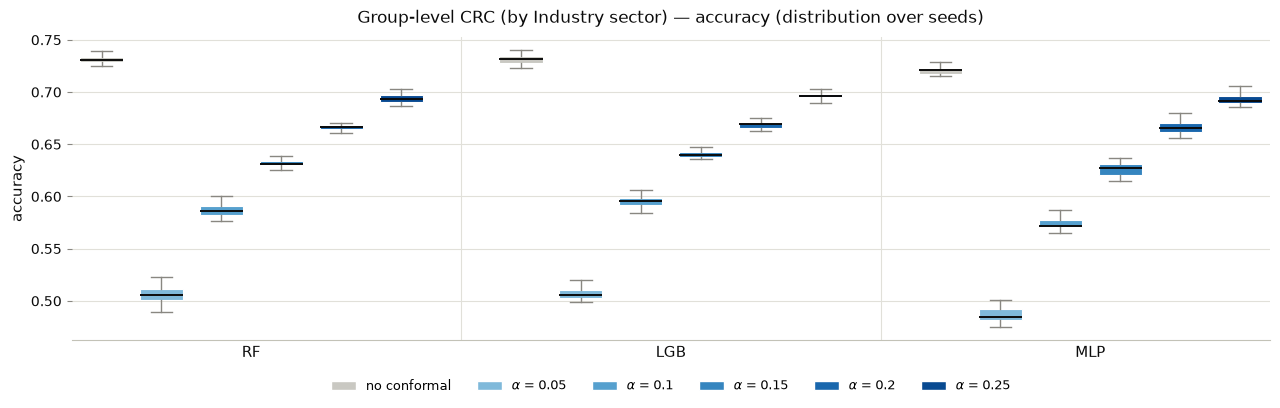

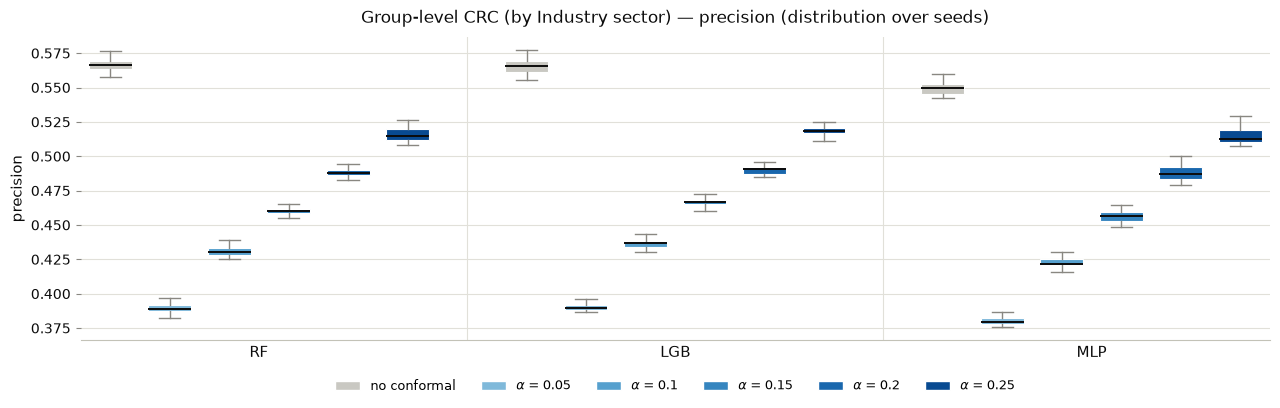

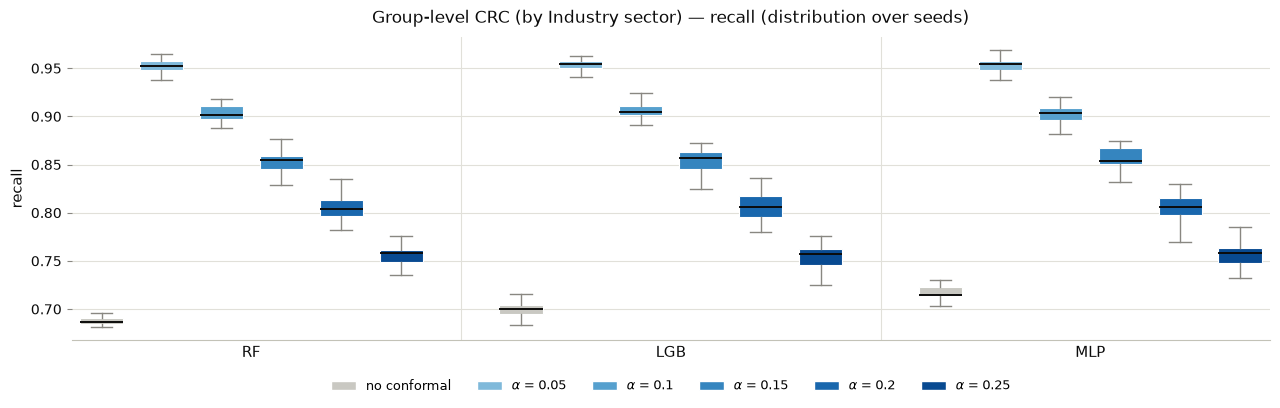

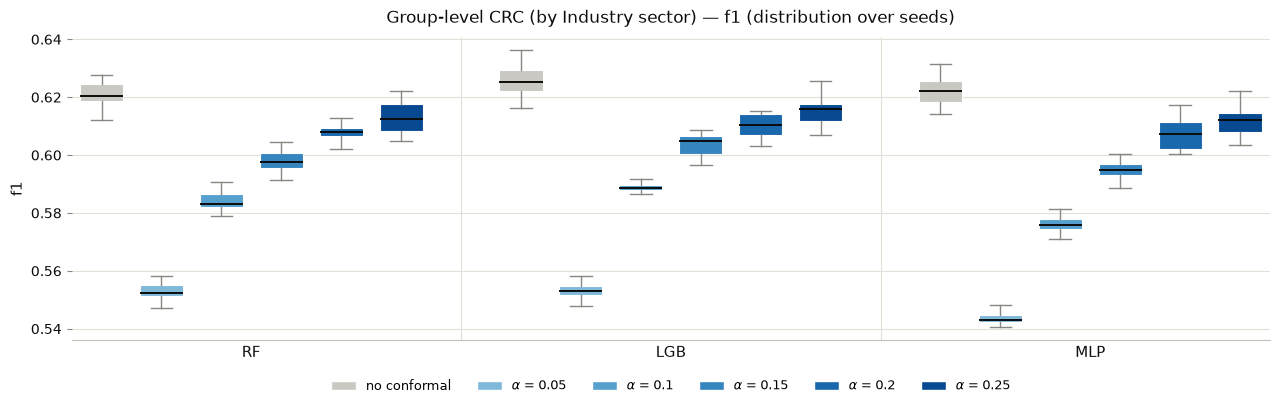

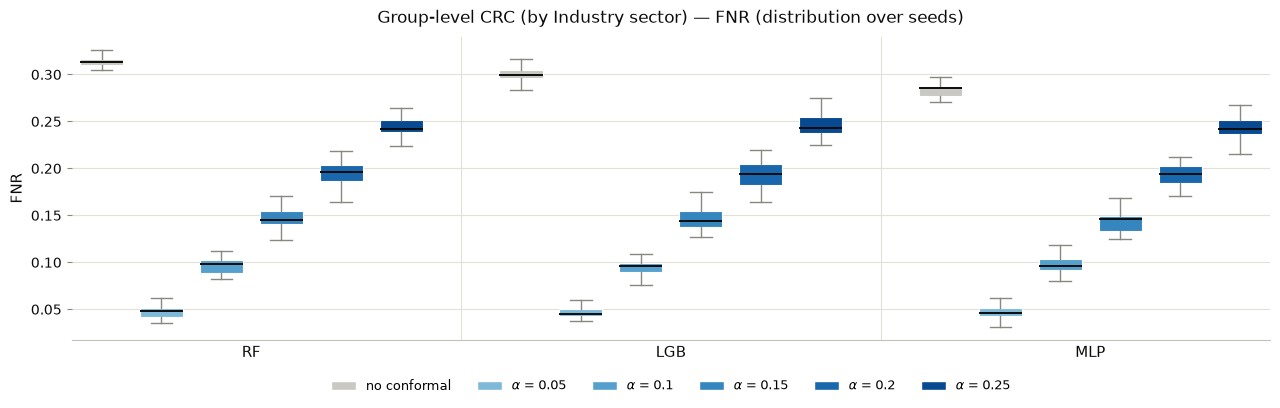

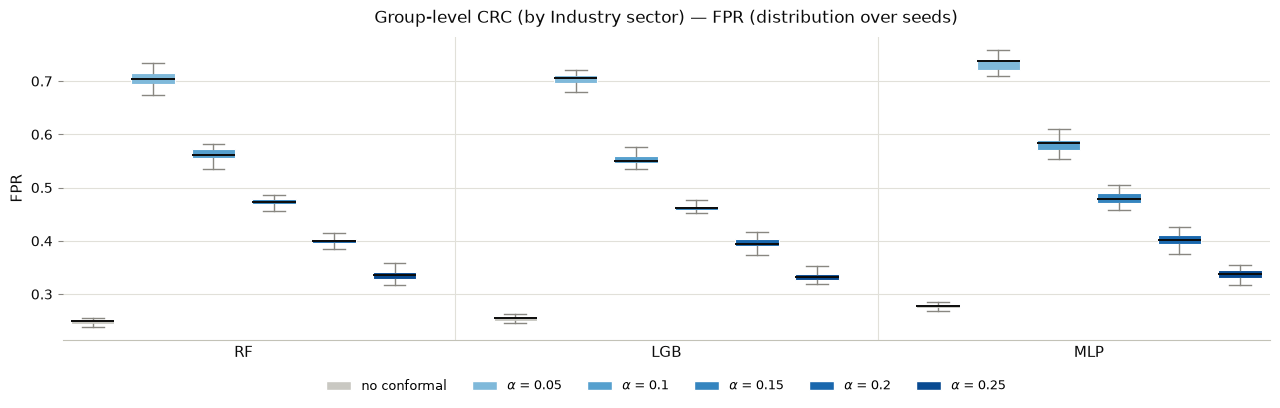

################  Group-level CRC calibrated by YearFounded cohort  ################


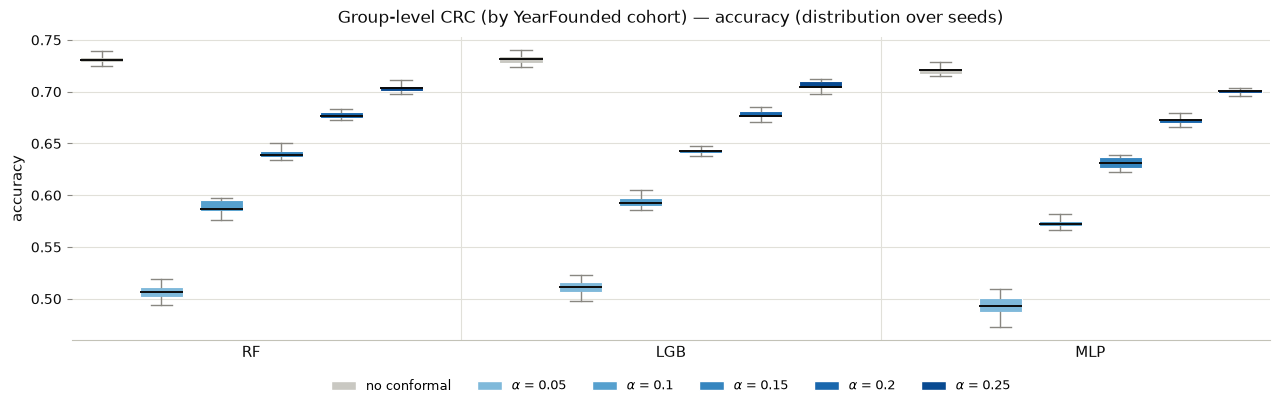

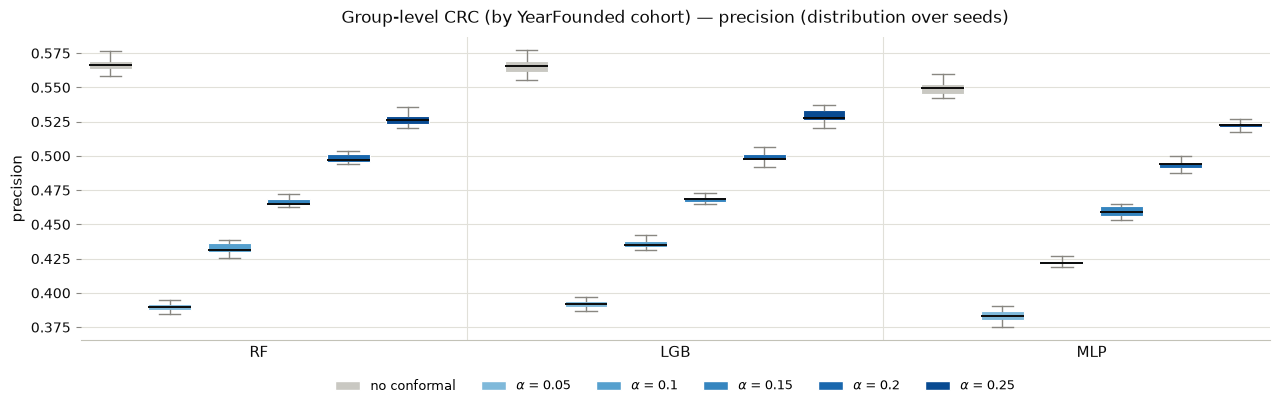

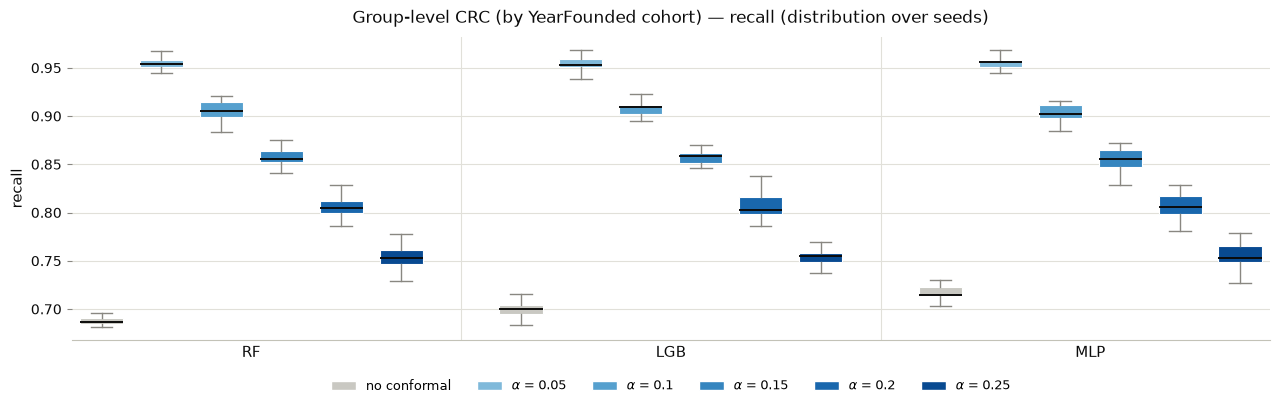

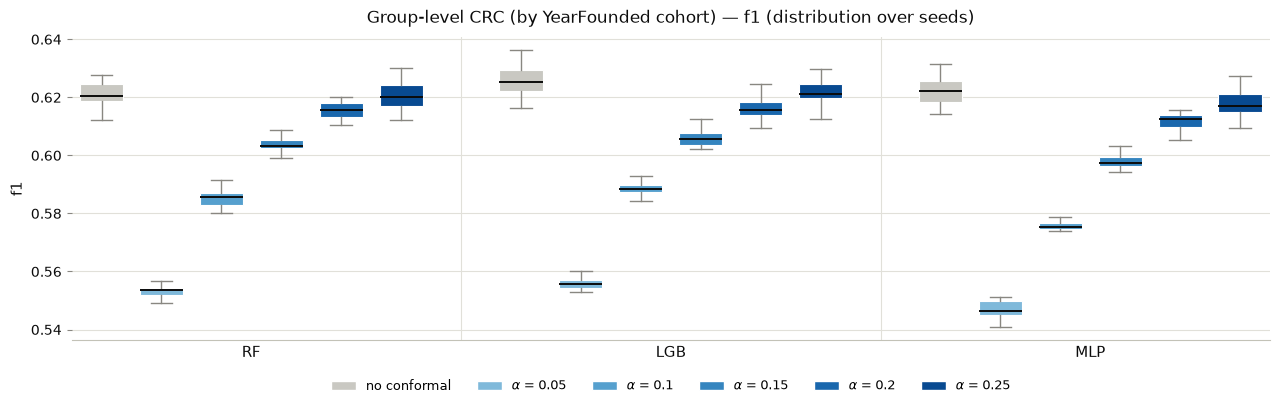

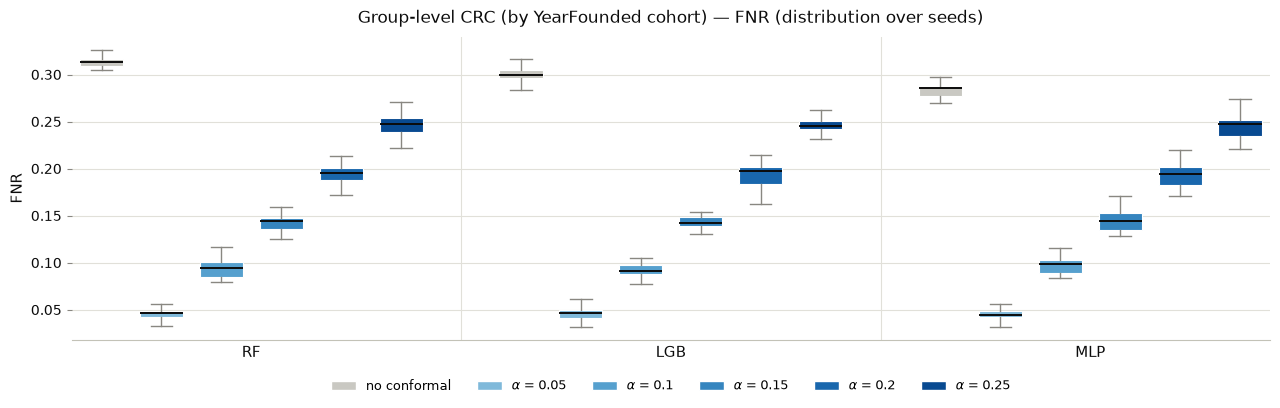

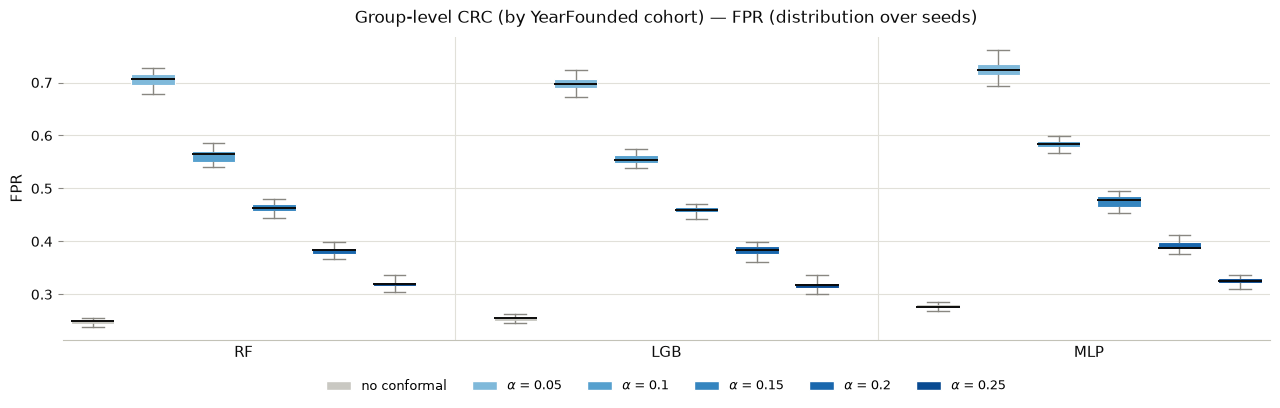

In [13]:
# Per-metric global boxplots, one set of figures per grouping.
for dim_name, _ in subgroup_dims:
    print(f"################  Group-level CRC calibrated by {dim_name}  ################")
    model_df = {m: df for (m, d), df in group_cal_store.items() if d == dim_name}
    plot_crc_metric_boxplots(model_df,
                             title_prefix=f"Group-level CRC (by {dim_name})")

### As RQ2 — subgroups under group-level calibration

The per-subgroup tables and plots, now with the **conditional** (Mondrian)
threshold: `FNR_cond` is pulled back toward `alpha`, with `FNR_marg` kept as
reference. `infeasible` flags groups with too few positive calibration examples.
Industry sector first, then founding-year cohort (with the per-model line plot).

=== RF — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,B2B,0.05,0.061,0.057,0.007,2183,581,False
1,B2C,0.05,0.085,0.047,NaN,3136,823,False
2,Energy,0.05,0.026,0.037,NaN,295,100,False
3,Financial Services,0.05,0.008,0.033,NaN,278,116,False
4,Healthcare,0.05,0.016,0.048,NaN,1618,693,False
5,Information Technology,0.05,0.045,0.046,NaN,5883,1966,False
6,Materials and Resources,0.05,0.019,0.043,NaN,242,95,False
7,B2B,0.10,0.131,0.105,0.005,2183,581,False
8,B2C,0.10,0.159,0.096,NaN,3136,823,False
9,Energy,0.10,0.054,0.088,NaN,295,100,False


=== LGB — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,B2B,0.05,0.066,0.050,NaN,2183,581,False
1,B2C,0.05,0.072,0.047,NaN,3136,823,False
2,Energy,0.05,0.016,0.029,NaN,295,100,False
3,Financial Services,0.05,0.008,0.037,NaN,278,116,False
4,Healthcare,0.05,0.016,0.044,NaN,1618,693,False
5,Information Technology,0.05,0.047,0.047,NaN,5883,1966,False
6,Materials and Resources,0.05,0.037,0.048,NaN,242,95,False
7,B2B,0.10,0.139,0.104,0.004,2183,581,False
8,B2C,0.10,0.151,0.090,NaN,3136,823,False
9,Energy,0.10,0.027,0.088,NaN,295,100,False


=== MLP — Industry sector (group-calibrated) ===


,Industry sector,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,B2B,0.05,0.054,0.058,0.008,2183,581,False
1,B2C,0.05,0.075,0.048,NaN,3136,823,False
2,Energy,0.05,0.043,0.042,NaN,295,100,False
3,Financial Services,0.05,0.009,0.036,NaN,278,116,False
4,Healthcare,0.05,0.022,0.046,NaN,1618,693,False
5,Information Technology,0.05,0.047,0.044,NaN,5883,1966,False
6,Materials and Resources,0.05,0.060,0.046,NaN,242,95,False
7,B2B,0.10,0.120,0.108,0.008,2183,581,False
8,B2C,0.10,0.151,0.098,NaN,3136,823,False
9,Energy,0.10,0.084,0.079,NaN,295,100,False


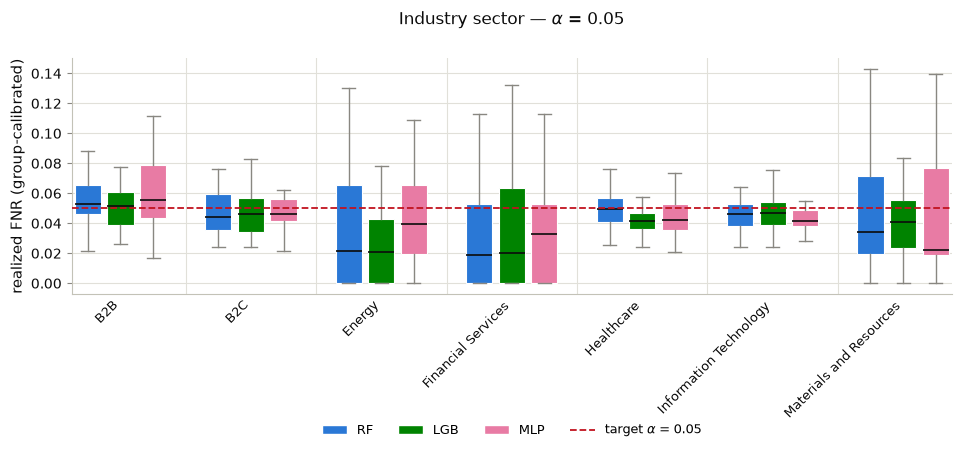

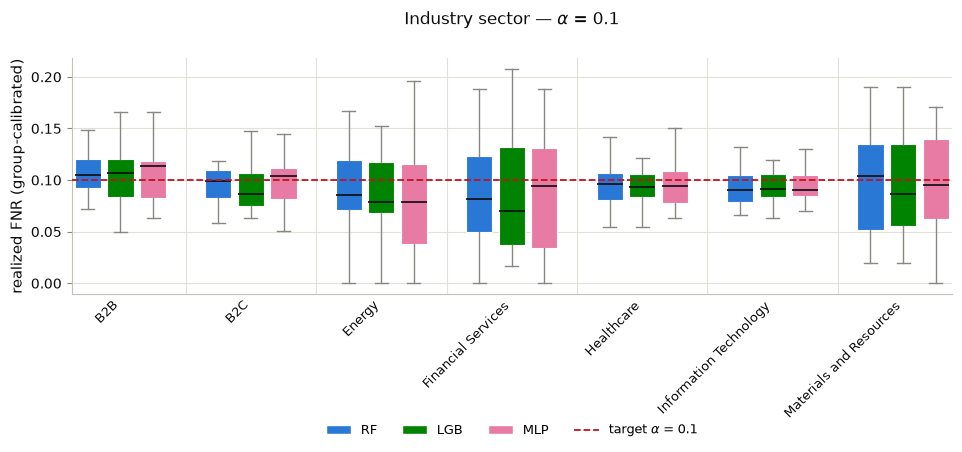

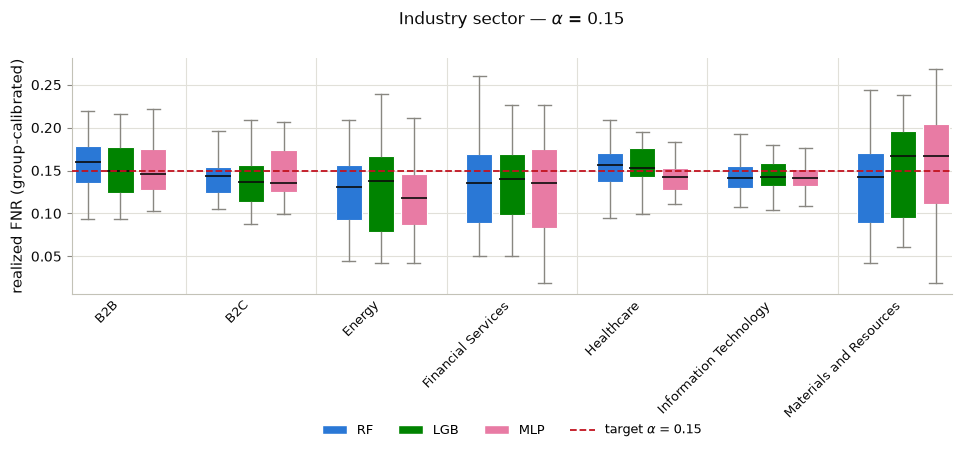

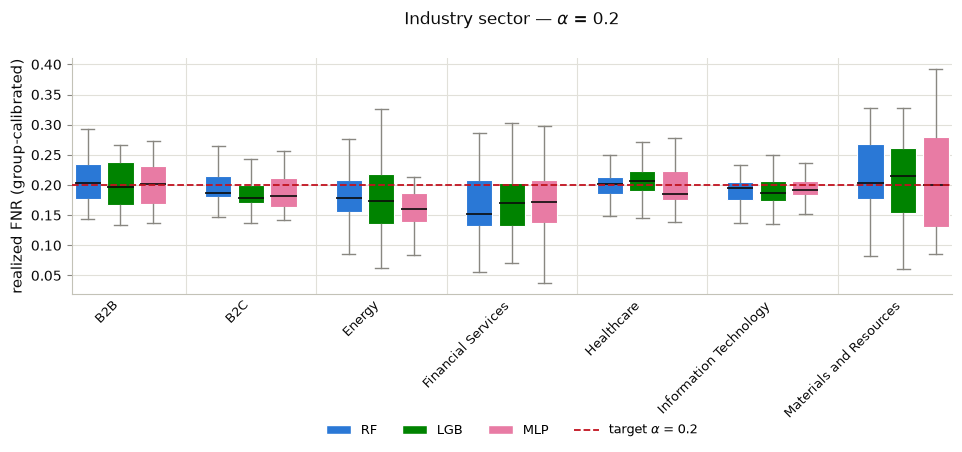

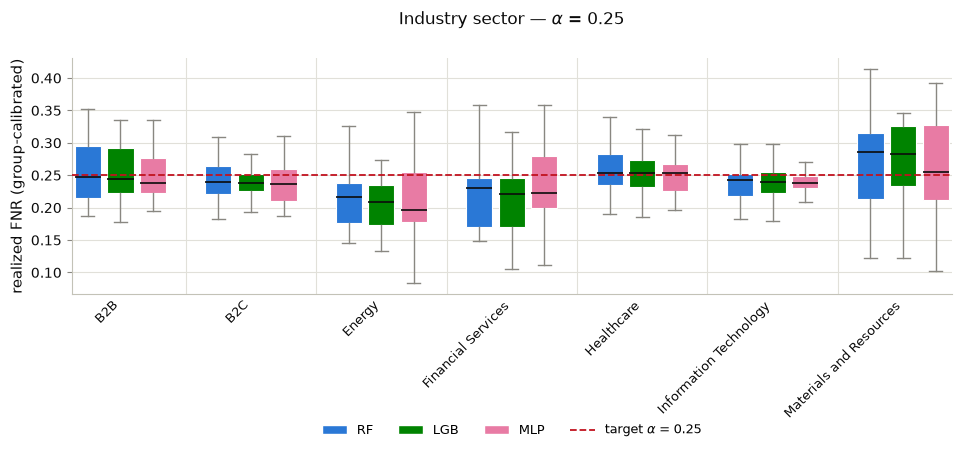

In [14]:
# Industry sector — conditional table then grouped boxplot.
cond_cols = ["group", "alpha", "FNR_marg", "FNR_cond", "FNR_cond - alpha",
             "n_pool", "n_pos_pool", "infeasible"]
dim_name = "Industry sector"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} (group-calibrated) ===")
    display(tab[cond_cols].rename(columns={"group": dim_name}))

sector_cond = {m: raw for (m, d), raw in subgroup_raw_cond.items() if d == dim_name}
plot_fnr_by_group_boxplots(sector_cond, dim_name, model_color,
                           ylabel="realized FNR (group-calibrated)")

=== RF — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.000,0.000,NaN,55,26,True
1,2009,0.05,0.007,0.030,NaN,240,102,False
2,2010,0.05,0.024,0.040,NaN,871,313,False
3,2011,0.05,0.047,0.043,NaN,1208,363,False
4,2012,0.05,0.057,0.049,NaN,1541,450,False
5,2013,0.05,0.052,0.047,NaN,1828,591,False
6,2014,0.05,0.056,0.043,NaN,2122,721,False
7,2015,0.05,0.043,0.052,0.002,2420,758,False
8,2016,0.05,0.050,0.047,NaN,2032,701,False
9,2017,0.05,0.060,0.048,NaN,1318,349,False


=== LGB — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.000,0.000,NaN,55,26,True
1,2009,0.05,0.007,0.036,NaN,240,102,False
2,2010,0.05,0.037,0.043,NaN,871,313,False
3,2011,0.05,0.069,0.047,NaN,1208,363,False
4,2012,0.05,0.068,0.049,NaN,1541,450,False
5,2013,0.05,0.049,0.045,NaN,1828,591,False
6,2014,0.05,0.049,0.045,NaN,2122,721,False
7,2015,0.05,0.039,0.050,NaN,2420,758,False
8,2016,0.05,0.040,0.048,NaN,2032,701,False
9,2017,0.05,0.048,0.047,NaN,1318,349,False


=== MLP — YearFounded cohort (group-calibrated) ===


,YearFounded cohort,alpha,FNR_marg,FNR_cond,FNR_cond - alpha,n_pool,n_pos_pool,infeasible
0,2008,0.05,0.000,0.000,NaN,55,26,True
1,2009,0.05,0.025,0.028,NaN,240,102,False
2,2010,0.05,0.043,0.045,NaN,871,313,False
3,2011,0.05,0.050,0.038,NaN,1208,363,False
4,2012,0.05,0.064,0.043,NaN,1541,450,False
5,2013,0.05,0.054,0.043,NaN,1828,591,False
6,2014,0.05,0.051,0.041,NaN,2122,721,False
7,2015,0.05,0.040,0.054,0.004,2420,758,False
8,2016,0.05,0.042,0.050,NaN,2032,701,False
9,2017,0.05,0.055,0.049,NaN,1318,349,False


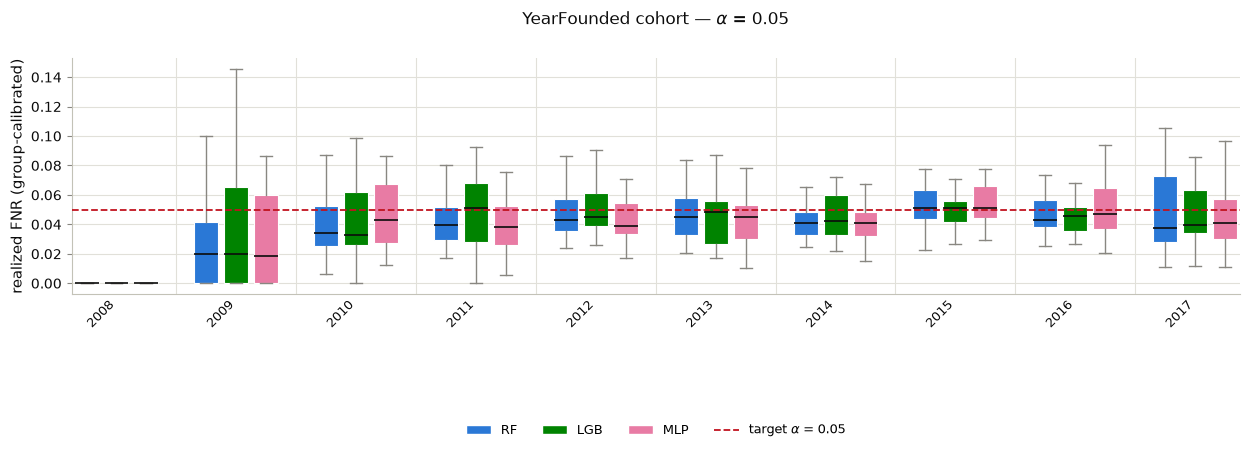

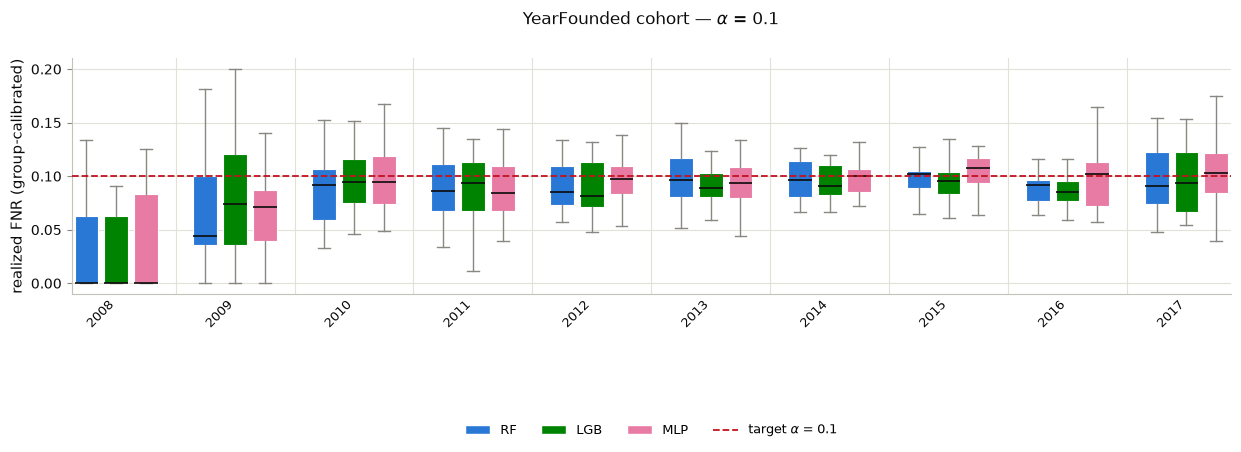

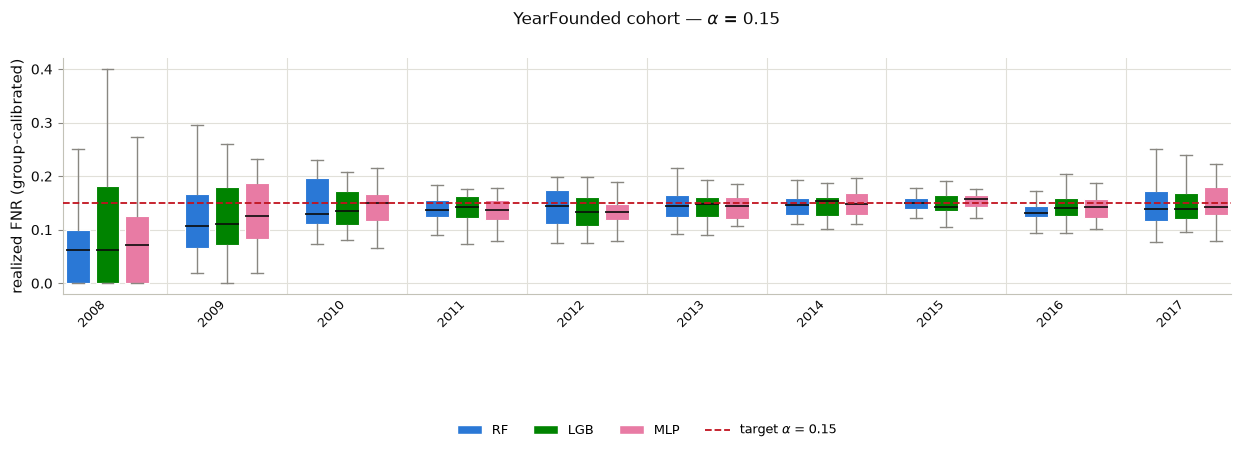

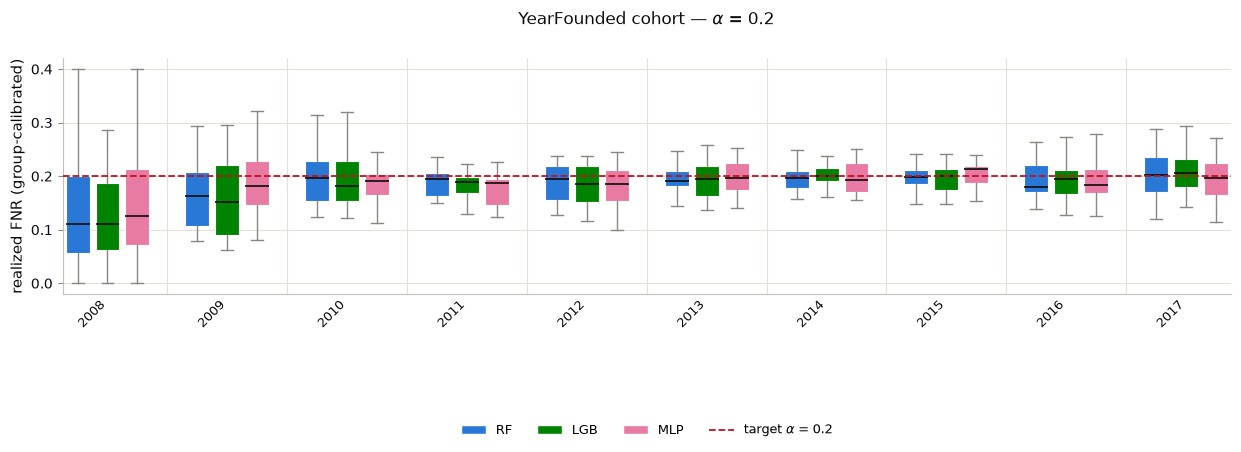

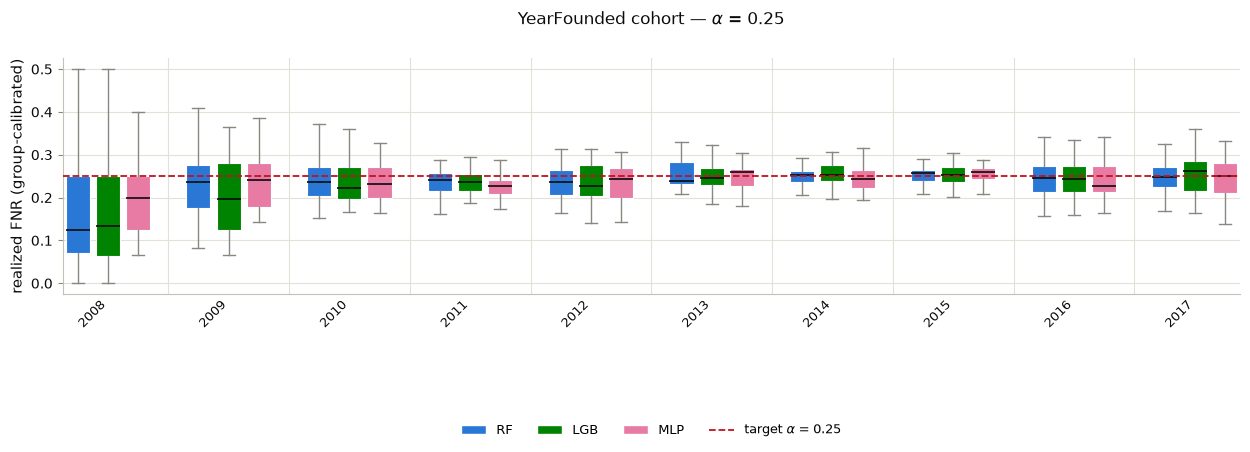

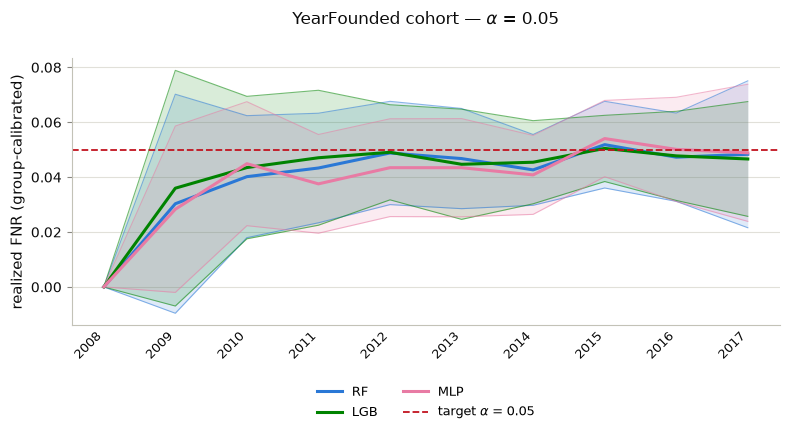

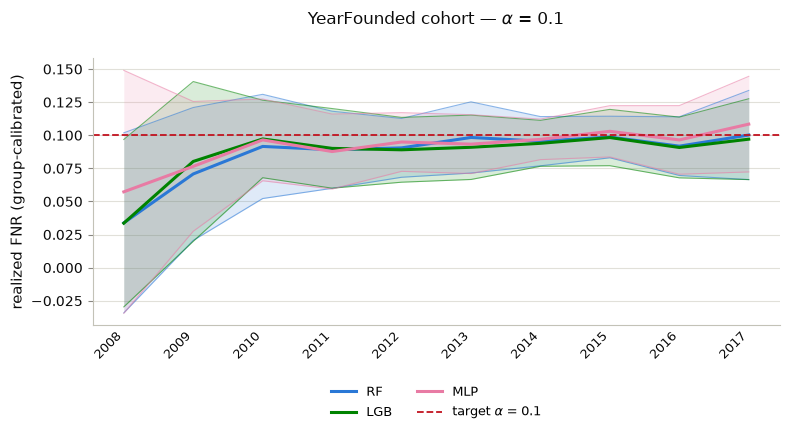

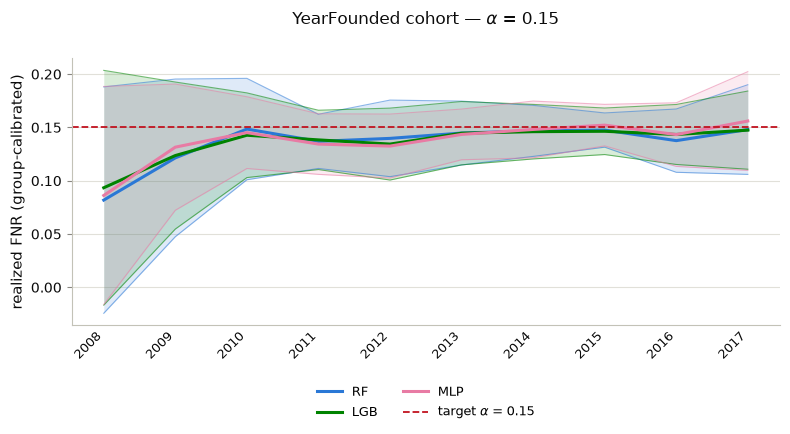

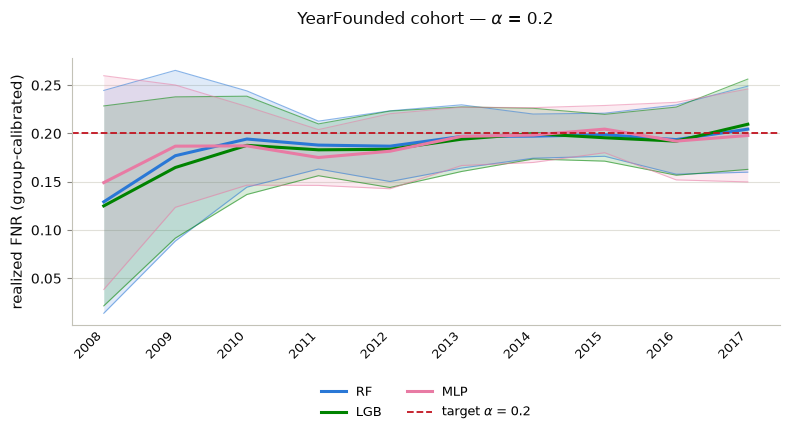

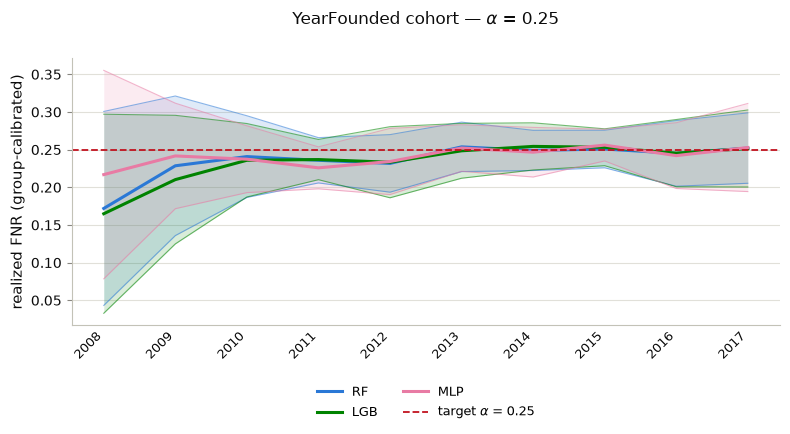

In [15]:
# YearFounded cohort — conditional table, grouped boxplot, per-model line plot.
cond_cols = ["group", "alpha", "FNR_marg", "FNR_cond", "FNR_cond - alpha",
             "n_pool", "n_pos_pool", "infeasible"]
dim_name = "YearFounded cohort"
for (model_type, d), tab in subgroup_tables.items():
    if d != dim_name:
        continue
    print(f"=== {model_type.upper()} — {dim_name} (group-calibrated) ===")
    display(tab[cond_cols].rename(columns={"group": dim_name}))

cohort_cond = {m: raw for (m, d), raw in subgroup_raw_cond.items() if d == dim_name}
plot_fnr_by_group_boxplots(cohort_cond, dim_name, model_color,
                           ylabel="realized FNR (group-calibrated)")
plot_fnr_by_group_lines(cohort_cond, dim_name, model_color,
                        ylabel="realized FNR (group-calibrated)")